# 2.1 EDA alternativo: validaciones por estación y franja horaria como variable objetivo

**Autor:** William Caro (`wcaro`) · **Tipo:** propuesta individual para **votación del grupo** · **Puntos de la rúbrica:** b, c (y base para d–h si se aprueba)

Este notebook **no reemplaza ni modifica** el notebook 02 ni ningún archivo del repositorio. Lee los mismos ZIP crudos de `data/raw/validaciones_troncal/` y guarda **todo lo que produce en carpetas propias**:

- tablas intermedias → `data/processed/wcaro/` (no se sube a GitHub, igual que el resto de `data/`)
- figuras → `docs/figs/wcaro/`

**Qué propone, en una frase:** sobre el blueprint de 2 niveles ya adoptado (Nivel 1 = perfiles por estación; Nivel 2 = índice de prioridad de refuerzo por estación × tipo de día × hora), estudiar a fondo la variable que alimenta todo el Nivel 2 — **el número de validaciones por estación, fecha y hora** — y evaluar si su histórico permite **anticipar la presión del día siguiente**. Es medible directamente con los registros, tiene una aplicación operativa clara (¿dónde y cuándo habrá más gente mañana?) y permite trabajar tanto estadística descriptiva/inferencial como Machine Learning.

**Contenido**
1. Pregunta propuesta y variable objetivo
2. De transacciones a la tabla estación–fecha–hora
3. ¿Qué cuenta como validación válida? (el caso de `Valor = 0`)
4. Descripción de la variable objetivo
5. Variables explicativas candidatas: horario, calendario, estación, línea
6. Variables históricas (actividad previa) y su relación con el objetivo
7. Qué aprovechar de las demás columnas
8. Siete insights concretos
9. Prueba de concepto: ¿el histórico reciente permite anticipar mañana?
10. Cómo encaja con Dask, Prefect, AWS y Grafana
11. Caso hipotético: cómo se le vendería esto al operador
12. **Propuesta para votación**

## 1. Pregunta propuesta y variable objetivo

> **¿Cómo se relacionan el horario, el calendario, la estación y su actividad histórica con el número de validaciones, y qué tan bien permiten anticipar la actividad del día siguiente?**

- **Variable objetivo** = lo que se busca explicar o predecir.
- **Variables explicativas** = la información que se usa para hacerlo.

La tabla original tiene **transacciones** (una fila = una pasada de tarjeta). Hay que transformarla para que **cada fila sea una estación, una fecha y una hora**:

$$
Y_{s,d,h} = \text{número de validaciones de la estación } s \text{ en la fecha } d \text{ y la hora } h
$$

**Relación con el plan actual del grupo (CLAUDE.md, reformulado el 1-oct):** la pregunta del grupo es *"¿En qué estaciones troncales y en qué franjas horarias de la semana se concentra la presión de demanda que justifica asignar personal de apoyo para la gestión de filas y el orden, y qué perfiles de demanda permiten organizar esos turnos?"*, con unidad de análisis **estación × día × hora** y variable objetivo principal el **índice de prioridad de refuerzo**. Esta propuesta **no compite con eso**:

- $Y_{s,d,h}$ es la **materia prima** del Nivel 2: `validaciones_promedio`, `ratio_vs_promedio_estacion`, `es_hora_critica` y `variabilidad` se calculan todas a partir de ella. Este notebook la estudia en detalle y aporta variables nuevas (transbordo, plataformas de alimentación, estabilidad).
- Lo que agrega es una pregunta complementaria: **¿el índice de prioridad de mañana se puede anticipar con el histórico de hoy?** Eso permite **evaluar con fechas futuras** (entrenar con días pasados y medir el error en días posteriores), algo que un ranking estático no ofrece. El plan ya contempla el pronóstico como "opcional / trabajo futuro"; aquí se prueba con datos si vale la pena.

In [1]:
import time, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

RAW = Path('../data/raw/validaciones_troncal')
EST = Path('../data/raw/estaciones')
OUT = Path('../data/processed/wcaro')          # carpeta propia, no toca lo del notebook 02
PIEZAS = OUT / 'piezas'
FIGS = Path('../docs/figs/wcaro')
for p in (OUT, PIEZAS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

# Festivos de Colombia 2026 (Ley Emiliani: los trasladables se corren al lunes)
FESTIVOS = pd.to_datetime([
    '2026-01-01', '2026-01-12', '2026-03-23', '2026-04-02', '2026-04-03', '2026-05-01',
    '2026-05-18', '2026-06-08', '2026-06-15', '2026-06-29', '2026-07-20', '2026-08-07',
    '2026-08-17', '2026-10-12', '2026-11-02', '2026-11-16', '2026-12-08', '2026-12-25',
])
HORAS_PICO = list(range(5, 10)) + list(range(16, 21))   # mismas ventanas del notebook 02

# Paleta (orden fijo: el color sigue a la categoria, nunca al ranking)
C = {'habil': '#2a78d6', 'sabado': '#eb6834', 'domingo': '#1baf7a', 'festivo': '#eda100'}
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = mcolors.LinearSegmentedColormap.from_list('azul', ['#f0efec', '#86b6ef', '#2a78d6', '#104281', '#0d366b'])
DIV = mcolors.LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': TINTA2, 'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': TINTA, 'lines.linewidth': 2,
    'legend.frameon': False, 'font.size': 9.5,
})
def guardar(nombre):
    plt.savefig(FIGS / nombre, dpi=150, bbox_inches='tight')

## 2. De transacciones a la tabla estación–fecha–hora

**Diseño escalable (mismo espíritu del flujo de Prefect):** cada ZIP diario se lee **una sola vez**, se agrega de inmediato y se guarda su resultado agregado en `data/processed/wcaro/piezas/`. Si mañana llega un archivo nuevo, solo se procesa ese; los demás se leen del caché.

Por cada archivo se guardan 5 agregados pequeños (no el dato crudo):

| Pieza | Llave | Para qué |
|---|---|---|
| `base` | estación, fecha, hora, perfil, tipo de tarifa, tipo de tarjeta, ¿valor = 0? | Variable objetivo + composición de usuarios |
| `acceso` | estación, acceso, fecha, hora | Reparto entre entradas de una misma estación |
| `dispositivo` | estación, dispositivo, fecha | Calidad de captura / nº de validadores |
| `linea` | estación, línea | Zona/troncal de cada estación |
| `nombre` | estación, nombre | Nombre legible |

Decisiones de limpieza (heredadas del notebook 01):
- `encoding='utf-8'` (corrección del grupo del 1-oct: el archivo es UTF-8; con latin1 cada tilde se corrompe, p. ej. "AmÃ©rica").
- Se agrupa por la **fecha real de `Fecha_Transaccion`**, no por el archivo (el "sangrado" de medianoche entre archivos queda en su fecha correcta).
- Código de estación = los 5 dígitos entre paréntesis al inicio de `Estacion_Parada`.
- Las fechas vienen como texto `YYYY-MM-DD HH:MM:SS` en los CSV (los números tipo Excel solo aparecían en la muestra abierta en hoja de cálculo).

In [2]:
COLS = ['Acceso_Estacion', 'Dispositivo', 'Estacion_Parada', 'Fecha_Transaccion', 'Linea',
        'Nombre_Perfil', 'Tipo_Tarifa', 'Tipo_Tarjeta', 'Valor']
TABLAS = ['base', 'acceso', 'dispositivo', 'linea', 'nombre']

def procesar_archivo(zip_path):
    t0 = time.time()
    df = pd.read_csv(zip_path, encoding='utf-8', usecols=COLS, engine='pyarrow')
    ts = pd.to_datetime(df['Fecha_Transaccion'], errors='coerce')
    n_crudas, n_fecha_invalida = len(df), int(ts.isna().sum())
    df = df[ts.notna()]
    ts = ts[ts.notna()]
    df = df.assign(fecha=ts.dt.normalize(), hora=ts.dt.hour.astype('int8'),
                   cod_estacion=df['Estacion_Parada'].str.extract(r'^\((\d+)\)', expand=False),
                   valor0=df['Valor'].eq(0))
    piezas = {
        'base': df.groupby(['cod_estacion', 'fecha', 'hora', 'Nombre_Perfil', 'Tipo_Tarifa',
                            'Tipo_Tarjeta', 'valor0'], observed=True).size(),
        'acceso': df.groupby(['cod_estacion', 'Acceso_Estacion', 'fecha', 'hora'], observed=True).size(),
        'dispositivo': df.groupby(['cod_estacion', 'Dispositivo', 'fecha'], observed=True).size(),
        'linea': df.groupby(['cod_estacion', 'Linea'], observed=True).size(),
        'nombre': df.groupby(['cod_estacion', 'Estacion_Parada'], observed=True).size(),
    }
    for nombre_t, s in piezas.items():
        s.rename('n').reset_index().to_parquet(PIEZAS / f'{zip_path.stem}__{nombre_t}.parquet', index=False)
    meta = pd.DataFrame([{'archivo': zip_path.name, 'filas_crudas': n_crudas,
                          'fecha_invalida': n_fecha_invalida, 'segundos': round(time.time() - t0, 1)}])
    meta.to_parquet(PIEZAS / f'{zip_path.stem}__meta.parquet', index=False)

inventario = []
for z in sorted(RAW.glob('*.zip')):
    en_cache = all((PIEZAS / f'{z.stem}__{t}.parquet').exists() for t in TABLAS + ['meta'])
    estado = 'cache'
    if not en_cache:
        try:
            procesar_archivo(z)
            estado = 'procesado ahora'
        except Exception as e:   # ZIP incompleto/corrupto: se reporta, no se adivina
            inventario.append({'archivo': z.name, 'estado': f'OMITIDO ({type(e).__name__})',
                               'MB_zip': round(z.stat().st_size / 2**20, 1)})
            continue
    meta = pd.read_parquet(PIEZAS / f'{z.stem}__meta.parquet').iloc[0].to_dict()
    inventario.append({**meta, 'estado': estado, 'MB_zip': round(z.stat().st_size / 2**20, 1)})

inventario = pd.DataFrame(inventario)
inventario

,archivo,filas_crudas,fecha_invalida,segundos,estado,MB_zip
0,validacionTroncal20260803.zip,1817362.0,0.0,12.4,procesado ahora,117.7
1,validacionTroncal20260804.zip,1879864.0,0.0,22.6,procesado ahora,121.6
2,validacionTroncal20260805.zip,1893704.0,0.0,26.7,procesado ahora,122.5
3,validacionTroncal20260806.zip,1837065.0,0.0,16.1,procesado ahora,118.7
4,validacionTroncal20260807.zip,525817.0,0.0,3.8,procesado ahora,32.2
5,validacionTroncal20260808.zip,1062209.0,0.0,9.1,procesado ahora,66.7
6,validacionTroncal20260809.zip,516440.0,0.0,7.8,procesado ahora,31.2
7,validacionTroncal20260810.zip,1751965.0,0.0,14.5,procesado ahora,113.3
8,validacionTroncal20260811.zip,1832551.0,0.0,14.9,procesado ahora,118.5
9,validacionTroncal20260812.zip,1852083.0,0.0,8.1,procesado ahora,119.7


In [3]:
ok = inventario[~inventario['estado'].str.startswith('OMITIDO')]
def leer(tabla):
    return pd.concat([pd.read_parquet(PIEZAS / f"{Path(a).stem}__{tabla}.parquet") for a in ok['archivo']],
                     ignore_index=True)

# Fechas "completas" = las fechas de los archivos leidos correctamente. Las colas de medianoche
# de un dia que no tiene archivo propio (sangrado) se quedan fuera para no crear dias parciales falsos.
FECHAS = pd.to_datetime(ok['archivo'].str.extract(r'(\d{8})')[0], format='%Y%m%d')

base = leer('base')
base = base[base['fecha'].isin(FECHAS)]
base = base.groupby(['cod_estacion', 'fecha', 'hora', 'Nombre_Perfil', 'Tipo_Tarifa', 'Tipo_Tarjeta', 'valor0'],
                    as_index=False)['n'].sum()

nombres = leer('nombre').groupby(['cod_estacion', 'Estacion_Parada'])['n'].sum().reset_index()
nombres = (nombres.sort_values('n', ascending=False).drop_duplicates('cod_estacion')
           .assign(nombre=lambda d: d['Estacion_Parada'].str.replace(r'^\(\d+\)\s*', '', regex=True))
           .set_index('cod_estacion')['nombre'])
lineas = leer('linea').groupby(['cod_estacion', 'Linea'])['n'].sum().reset_index()
lineas = (lineas.sort_values('n', ascending=False).drop_duplicates('cod_estacion')
          .assign(linea=lambda d: d['Linea'].str.replace(r'^\(\d+\)\s*', '', regex=True))
          .set_index('cod_estacion')['linea'])

print(f"Archivos usados: {len(ok)} de {len(inventario)}  |  fechas: {FECHAS.min():%Y-%m-%d} a {FECHAS.max():%Y-%m-%d}")
print(f"Validaciones totales en fechas completas: {base['n'].sum():,}")
print(f"Filas crudas leidas (incluye sangrado de medianoche): {ok['filas_crudas'].sum():,}")
print(f"Fechas invalidas descartadas: {ok['fecha_invalida'].sum():,}")
print(f"Estaciones distintas: {base['cod_estacion'].nunique()}")

Archivos usados: 11 de 12  |  fechas: 2026-08-03 a 2026-08-13
Validaciones totales en fechas completas: 16,806,183
Filas crudas leidas (incluye sangrado de medianoche): 16,806,193.0
Fechas invalidas descartadas: 0.0
Estaciones distintas: 150


**Lectura — qué datos entraron en esta corrida:**
- **11 de 12 ZIP** leídos (3 al 13 de agosto de 2026): **16,806,183 validaciones** en 150 estaciones. El ZIP del **14 de agosto está incompleto/corrupto** en esta máquina (67.6 MB frente a ~120 MB de un día hábil; `BadZipFile`): se reporta y se omite, no se adivina. Hay que volver a descargarlo.
- Las semanas de septiembre (14–20 sep) **no están descargadas en este equipo**. El notebook está hecho para usar automáticamente todo lo que haya en `data/raw/`: si se corre en el equipo que tiene las 3 semanas, todas las cifras se recalculan sin tocar el código (y aparecería el efecto "mes").
- 0 fechas inválidas; solo 10 filas de "sangrado" de medianoche quedaron fuera por pertenecer a fechas sin archivo propio (16,806,193 leídas → 16,806,183 usadas).
- Cada archivo tarda entre 3 y 18 s en leerse con el motor `pyarrow`; con el caché por archivo, volver a correr el notebook no relee los ZIP.

## 3. ¿Qué cuenta como validación válida? El caso de `Valor = 0`

Antes de contar hay que confirmar qué registros son validaciones reales. **No se descartan automáticamente los de valor cero** — primero se mira qué son.

In [4]:
tarifa_valor = base.pivot_table(index='Tipo_Tarifa', columns='valor0', values='n', aggfunc='sum', fill_value=0)
tarifa_valor.columns = ['valor > 0', 'valor = 0']
tarifa_valor['% del total'] = (tarifa_valor.sum(axis=1) / tarifa_valor.values.sum() * 100).round(2)
tarifa_valor

,valor > 0,valor = 0,% del total
Tipo_Tarifa,,,
"1,0",14445080,163945,86.93
"2,0",0,2123667,12.64
"3,0",0,73491,0.44


In [5]:
perfil_tarifa = base.pivot_table(index='Nombre_Perfil', columns='Tipo_Tarifa', values='n', aggfunc='sum', fill_value=0)
perfil_tarifa['% tarifa != 1'] = ((perfil_tarifa.sum(axis=1) - perfil_tarifa.get('1,0', 0)) / perfil_tarifa.sum(axis=1) * 100).round(1)
perfil_tarifa.sort_values('1,0', ascending=False)

Tipo_Tarifa,"1,0","2,0","3,0",% tarifa != 1
Nombre_Perfil,,,,
(001) Adulto,6890099,1528758,50336,18.6
(001) Anonymous,5000100,0,0,0.0
(002) Adulto Mayor,1147092,233910,9850,17.5
(006) Apoyo Ciudadano,532895,122668,4404,19.3
(101) Adulto PV,410688,85260,2473,17.6
(009) Apoyo Ciudadano Reexpedición,397105,106733,4468,21.9
(005) Discapacidad,231046,46338,1960,17.3


In [6]:
# Las pocas validaciones con tarifa 1 y valor 0: ¿de que perfil son?
raras = base[(base['Tipo_Tarifa'] == '1,0') & base['valor0']]
print(f"Tarifa 1 con valor 0: {raras['n'].sum():,} ({raras['n'].sum() / base['n'].sum() * 100:.2f}% del total)")
raras.groupby('Nombre_Perfil')['n'].sum().sort_values(ascending=False)

Tarifa 1 con valor 0: 163,945 (0.98% del total)


Nombre_Perfil
(001) Adulto                          88036
(001) Anonymous                       45288
(002) Adulto Mayor                    14073
(006) Apoyo Ciudadano                  6206
(009) Apoyo Ciudadano Reexpedición     4199
(101) Adulto PV                        3632
(005) Discapacidad                     2511
Name: n, dtype: int64

**Lectura — los registros de valor 0 NO se descartan:**
- **13.1% de las validaciones tienen `Valor = 0`**, y casi todas (12.6% + 0.4%) son exactamente las de **`Tipo_Tarifa` 2 y 3**: tarifa 2 y 3 **nunca** cobran, tarifa 1 casi siempre cobra. Es la firma de un **transbordo** (el sistema no cobra el segundo/tercer abordaje dentro de la ventana de integración). Coincide con que la tarjeta anónima (`Anonymous` = tullave Básica) tiene **0% de tarifa 2/3**: el beneficio de transbordo solo aplica a tarjetas personalizadas.
- Queda un 0.98% con tarifa 1 y valor 0, repartido en todos los perfiles (no solo subsidios). Sin diccionario oficial no se puede afirmar qué son (posibles cortesías o validaciones especiales); se marca como **pregunta abierta para el diccionario de datos de TransMilenio**.
- **Decisión:** para medir **actividad en la estación**, una persona que transborda sí entra por el torniquete y sí ocupa la plataforma → **cuenta como validación**. Si se excluyeran los valor 0, la demanda de las estaciones de transbordo quedaría subestimada hasta en más de 50% (ver 7.4). Se guarda además la columna `validaciones_valor0` por si el grupo prefiere otro criterio.

### 3.1 La tabla del objetivo: `panel` (estación × fecha × hora)

Se construye la **malla completa**: toda estación × toda fecha × las 24 horas, rellenando con 0 donde no hubo validaciones. Esto es importante para un modelo de conteos: "no hubo nadie" es un dato (0), no un faltante.

In [7]:
y = base.groupby(['cod_estacion', 'fecha', 'hora'])['n'].sum()
y0 = base[base['valor0']].groupby(['cod_estacion', 'fecha', 'hora'])['n'].sum()
malla = pd.MultiIndex.from_product([sorted(base['cod_estacion'].unique()), sorted(FECHAS), range(24)],
                                   names=['cod_estacion', 'fecha', 'hora'])
panel = pd.DataFrame({'validaciones': y.reindex(malla, fill_value=0),
                      'validaciones_valor0': y0.reindex(malla, fill_value=0)}).reset_index()

panel['nombre'] = panel['cod_estacion'].map(nombres)
panel['linea'] = panel['cod_estacion'].map(lineas)
panel['dow'] = panel['fecha'].dt.dayofweek
panel['dia_semana'] = panel['dow'].map(dict(enumerate(['lun', 'mar', 'mie', 'jue', 'vie', 'sab', 'dom'])))
panel['festivo'] = panel['fecha'].isin(FESTIVOS)
panel['tipo_dia'] = np.select([panel['festivo'], panel['dow'] == 5, panel['dow'] == 6],
                              ['festivo', 'sabado', 'domingo'], 'habil')
panel['mes'] = panel['fecha'].dt.month
print(f"panel: {len(panel):,} filas = {panel['cod_estacion'].nunique()} estaciones x "
      f"{panel['fecha'].nunique()} fechas x 24 horas")
assert panel['validaciones'].sum() == base['n'].sum()   # nada se pierde al pasar a la malla
panel[panel['hora'].between(6, 8)].sort_values(['fecha', 'cod_estacion', 'hora']).head(6)

panel: 39,600 filas = 150 estaciones x 11 fechas x 24 horas


,cod_estacion,fecha,hora,validaciones,validaciones_valor0,nombre,linea,dow,dia_semana,festivo,tipo_dia,mes
6,02000,2026-08-03,6,9262,422,Portal Norte - Unicervantes,Zona B AutoNorte,0,lun,False,habil,8
7,02000,2026-08-03,7,9362,407,Portal Norte - Unicervantes,Zona B AutoNorte,0,lun,False,habil,8
8,02000,2026-08-03,8,6139,272,Portal Norte - Unicervantes,Zona B AutoNorte,0,lun,False,habil,8
270,02001,2026-08-03,6,1167,134,Centro Comercial Santa Fe,Zona B AutoNorte,0,lun,False,habil,8
271,02001,2026-08-03,7,1323,152,Centro Comercial Santa Fe,Zona B AutoNorte,0,lun,False,habil,8
272,02001,2026-08-03,8,689,56,Centro Comercial Santa Fe,Zona B AutoNorte,0,lun,False,habil,8


Así se ve la tabla propuesta: **una fila = una estación, una fecha y una hora**, con su número de validaciones (la variable objetivo) y las variables de calendario derivadas. La suma total coincide con la de los registros crudos (se verificó con `assert`).

## 4. Descripción de la variable objetivo $Y_{s,d,h}$

In [8]:
Y = panel['validaciones']
operacion = panel[panel['hora'].between(4, 23)]
resumen_y = pd.DataFrame({
    'todas las horas': Y.describe(percentiles=[.25, .5, .75, .9, .99]),
    'horas de operacion (4-23h)': operacion['validaciones'].describe(percentiles=[.25, .5, .75, .9, .99]),
}).round(1)
print(f"% de celdas en cero: {(Y == 0).mean() * 100:.1f}%  (en horas de operacion: {(operacion['validaciones'] == 0).mean() * 100:.1f}%)")
print(f"Media = {Y.mean():.1f}  |  Varianza = {Y.var():,.0f}  |  Varianza / Media = {Y.var() / Y.mean():,.0f}")
print(f"Asimetria = {stats.skew(Y):.2f}")
resumen_y

% de celdas en cero: 21.1%  (en horas de operacion: 6.3%)
Media = 424.4  |  Varianza = 855,558  |  Varianza / Media = 2,016
Asimetria = 6.13


,todas las horas,horas de operacion (4-23h)
count,39600.0,33000.0
mean,424.4,508.8
std,925.0,991.9
min,0.0,0.0
25%,6.0,59.0
50%,143.0,217.0
75%,423.0,520.0
90%,1037.0,1217.0
99%,4595.1,5072.1
max,15308.0,15308.0


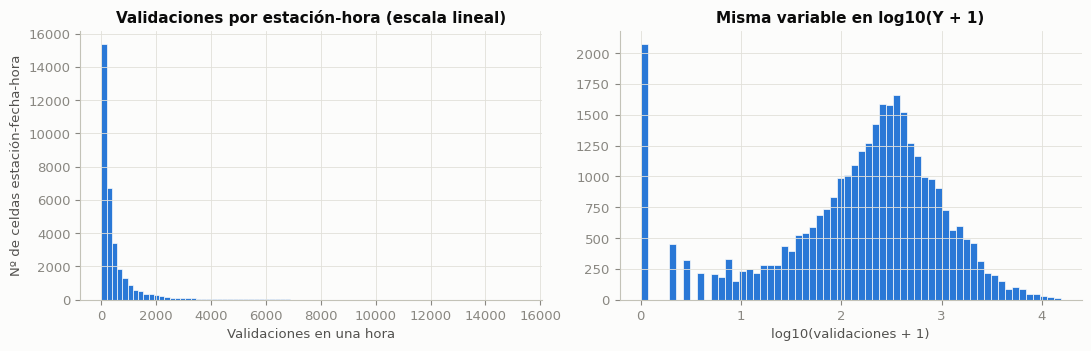

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(operacion['validaciones'], bins=80, color=C['habil'], edgecolor='#fcfcfb', linewidth=0.5)
axes[0].set_title('Validaciones por estación-hora (escala lineal)')
axes[0].set_xlabel('Validaciones en una hora'); axes[0].set_ylabel('Nº de celdas estación-fecha-hora')
axes[1].hist(np.log10(operacion['validaciones'] + 1), bins=60, color=C['habil'], edgecolor='#fcfcfb', linewidth=0.5)
axes[1].set_title('Misma variable en log10(Y + 1)')
axes[1].set_xlabel('log10(validaciones + 1)')
plt.tight_layout(); guardar('01_distribucion_objetivo.png'); plt.show()

**Lectura — cómo es la variable objetivo:**
- Es un **conteo** (entero ≥ 0) **muy sesgado**: mediana de 217 validaciones/hora en horas de operación, pero media de 509 y máximo de 15,308 (Portal Américas, 6 a. m.). Asimetría = 6.1.
- **Varianza ≈ 2,000 veces la media** → sobredispersión extrema. Un modelo de Poisson "puro" (varianza = media) no sirve tal cual; se necesita **binomial negativa**, quasi-Poisson o un modelo que prediga en escala log. Por eso aquí se usa la **devianza de Poisson** solo como medida de ajuste y un Gradient Boosting con pérdida Poisson (que modela la media en escala log, no exige varianza = media).
- 21% de celdas en cero, pero casi todos son la madrugada (0–3 h, sin operación). En horas de operación solo 6.3% son cero (estaciones muy pequeñas, temporales, corrales de bicicletas).
- En escala log la distribución es casi simétrica: cualquier gráfico o modelo lineal debe trabajar en log.

## 5. Variables explicativas candidatas

**Todavía no se puede afirmar que estén correlacionadas: son candidatas para comprobar.** Para variables **categóricas** (hora como franja, día, estación, línea) se comparan **distribuciones, medias y medianas** — no se les asigna un código numérico arbitrario para calcular Pearson sobre él.

| Variable | Cómo se obtiene | Qué relación se investiga |
|---|---|---|
| Hora | `Fecha_Transaccion` | Madrugada vs. mañana vs. tarde vs. noche |
| Día de semana | Derivado de la fecha | Lunes, viernes, sábado… |
| Festivo | Calendario propio (2026) | Diferencia frente a días comparables |
| Mes | Derivado de la fecha | Cambios a lo largo del año |
| Estación | Código de `Estacion_Parada` | Diferencias de volumen |
| Zona / línea | `Linea` | Patrones compartidos por ubicación |
| Validaciones del día anterior, misma hora | Histórico agregado | Persistencia (sección 6) |
| Validaciones de 7 días antes, misma hora | Histórico agregado | Patrón semanal (sección 6) |
| Promedio de días comparables previos | Solo fechas anteriores | Nivel habitual (sección 6) |
| Variabilidad histórica | Dispersión en días previos | Estabilidad (sección 6) |
| Vacaciones, eventos, clima | Información externa | Fuera del alcance de este notebook (punto c) |

### 5.1 Hora del día × tipo de día

Fechas por tipo de dia: {'domingo': 1, 'festivo': 1, 'habil': 8, 'sabado': 1}


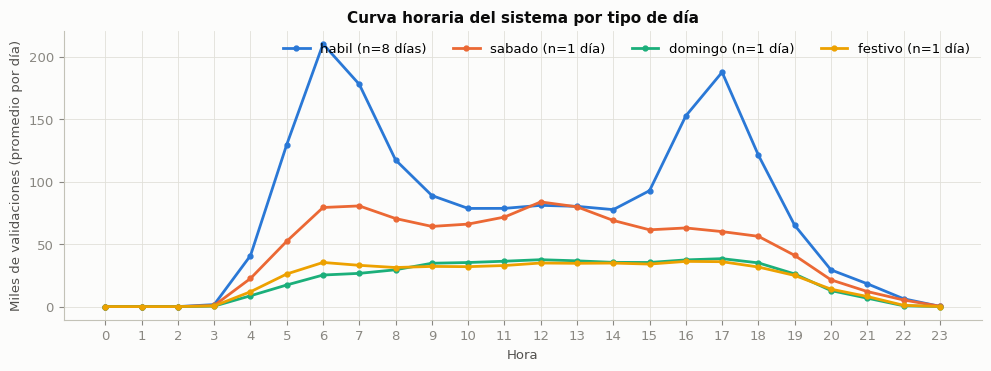

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
tipo_dia,,,,,,,,,,,,,,,,,,,,,,,,
domingo,0.0,0.0,0.0,0.4,8.7,17.3,25.3,26.6,29.5,34.7,35.3,36.4,37.6,36.7,35.4,35.3,37.4,38.4,35.0,26.1,12.8,6.8,0.7,0.0
festivo,0.0,0.0,0.0,0.5,11.9,26.1,35.4,33.1,31.3,32.2,32.0,32.9,34.9,34.7,34.9,34.1,36.2,36.0,31.7,25.0,14.0,8.1,1.0,0.0
habil,0.0,0.0,0.0,1.6,40.9,129.9,210.4,178.0,117.4,89.0,78.6,78.7,81.1,80.3,77.7,92.9,152.8,187.8,121.3,65.1,29.4,18.3,6.3,0.2
sabado,0.0,0.0,0.0,0.9,22.5,52.4,79.4,80.6,70.5,64.2,66.1,71.7,83.8,79.9,69.0,61.5,63.0,60.1,56.3,41.0,21.4,12.1,5.3,0.3


In [10]:
dias_tipo = panel.groupby('tipo_dia')['fecha'].nunique()
print('Fechas por tipo de dia:', dias_tipo.to_dict())
curva = panel.groupby(['tipo_dia', 'hora'])['validaciones'].sum().unstack(0).div(dias_tipo)

fig, ax = plt.subplots(figsize=(10, 3.8))
for t in [t for t in ['habil', 'sabado', 'domingo', 'festivo'] if t in curva]:
    ax.plot(curva.index, curva[t] / 1000, color=C[t], marker='o', markersize=3.5,
            label=f'{t} (n={dias_tipo[t]} día{"s" if dias_tipo[t] > 1 else ""})')
ax.set_xticks(range(24)); ax.set_xlabel('Hora'); ax.set_ylabel('Miles de validaciones (promedio por día)')
ax.set_title('Curva horaria del sistema por tipo de día'); ax.legend(ncol=4, loc='upper right')
plt.tight_layout(); guardar('02_curva_hora_tipo_dia.png'); plt.show()
(curva / 1000).round(1).T

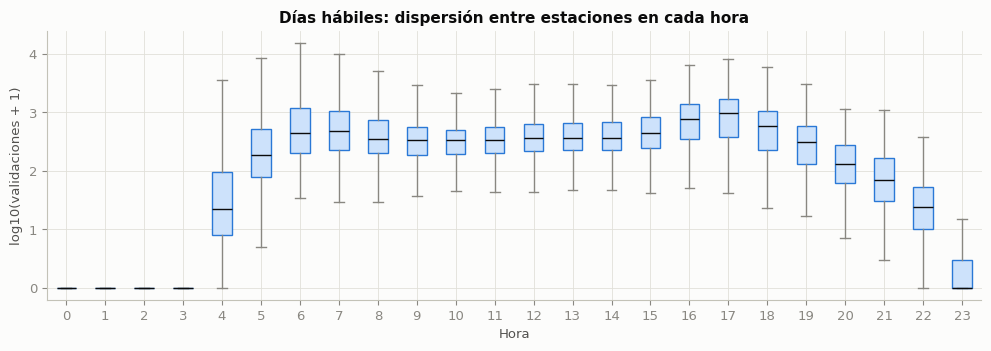

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
mean,0.0,0.0,0.0,11.0,272.0,866.0,1403.0,1187.0,783.0,593.0,524.0,525.0,541.0,535.0,518.0,619.0,1019.0,1252.0,809.0,434.0,196.0,122.0,42.0,1.0
median,0.0,0.0,0.0,0.0,21.0,188.0,448.0,468.0,352.0,337.0,330.0,340.0,356.0,367.0,368.0,448.0,768.0,952.0,572.0,311.0,130.0,69.0,23.0,0.0
std,0.0,0.0,0.0,47.0,797.0,1924.0,2535.0,1950.0,1190.0,796.0,622.0,575.0,552.0,519.0,475.0,577.0,993.0,1254.0,856.0,451.0,190.0,155.0,87.0,3.0


In [11]:
# Distribucion (no solo la media) por hora en dias habiles: mediana y rango intercuartil entre estaciones
hab = panel[panel['tipo_dia'] == 'habil']
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot([np.log10(hab.loc[hab['hora'] == h, 'validaciones'] + 1) for h in range(24)],
           tick_labels=list(range(24)), showfliers=False, patch_artist=True,
           boxprops=dict(facecolor='#cde2fb', edgecolor=C['habil']), medianprops=dict(color=TINTA),
           whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS))
ax.set_xlabel('Hora'); ax.set_ylabel('log10(validaciones + 1)')
ax.set_title('Días hábiles: dispersión entre estaciones en cada hora')
plt.tight_layout(); guardar('03_boxplot_hora_habil.png'); plt.show()
hab.groupby('hora')['validaciones'].agg(['mean', 'median', 'std']).round(0).T

**Lectura — la hora es la variable con la forma más fuerte, pero depende del tipo de día:**
- **Día hábil:** dos picos muy marcados — **6 a. m. (210 mil validaciones/hora en todo el sistema)** y **5 p. m. (188 mil)** — con un valle de ~80 mil al mediodía.
- **Sábado** (1 fecha): sin picos de commuting, meseta de 65–84 mil entre 6 a. m. y 1 p. m.
- **Domingo y festivo** (1 fecha cada uno): curvas casi idénticas, planas, ~30–38 mil/hora todo el día — confirma con otra semana lo que vio el notebook 02.
- El boxplot muestra que **dentro de una misma hora** la diferencia entre estaciones es enorme (en las 6 a. m. la media es 1,403 pero la mediana 448): la hora por sí sola no alcanza, hay que cruzarla con la estación (sección 5.4).

### 5.2 Día de la semana, festivo y mes

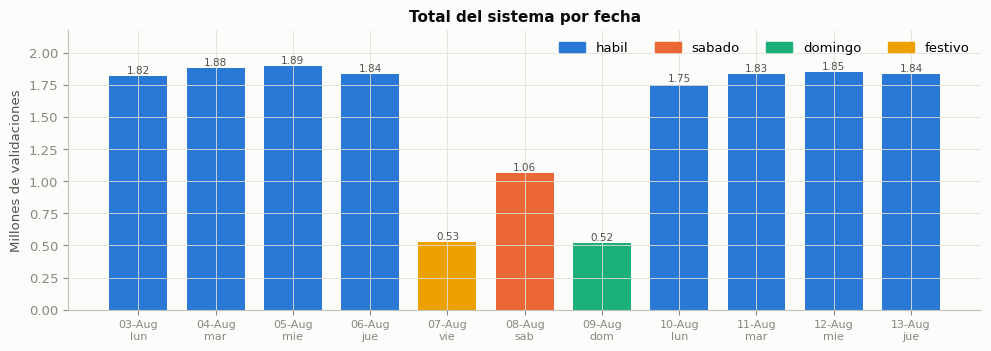

,promedio_diario,n_fechas,indice_vs_habil
dia_semana,,,
lun,1784658.0,2,0.97
mar,1856205.0,2,1.01
mie,1872882.0,2,1.02
jue,1837105.0,2,1.00
sab,1062203.0,1,0.58
dom,516447.0,1,0.28


In [12]:
por_fecha = panel.groupby(['fecha', 'dia_semana', 'tipo_dia'])['validaciones'].sum().reset_index()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(por_fecha)), por_fecha['validaciones'] / 1e6, width=0.75,
       color=[C[t] for t in por_fecha['tipo_dia']])
ax.set_xticks(range(len(por_fecha)))
ax.set_xticklabels([f"{f:%d-%b}\n{d}" for f, d in zip(por_fecha['fecha'], por_fecha['dia_semana'])], fontsize=8)
for i, v in enumerate(por_fecha['validaciones'] / 1e6):
    ax.text(i, v + 0.02, f'{v:.2f}', ha='center', fontsize=7.5, color=TINTA2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C[t], label=t) for t in ['habil', 'sabado', 'domingo', 'festivo'] if t in set(por_fecha['tipo_dia'])],
          ncol=4, loc='upper right')
ax.set_ylabel('Millones de validaciones'); ax.set_title('Total del sistema por fecha')
ax.set_ylim(0, por_fecha['validaciones'].max() / 1e6 * 1.15)
plt.tight_layout(); guardar('04_total_por_fecha.png'); plt.show()

dow_tab = (panel[~panel['festivo']].groupby(['dow', 'dia_semana', 'fecha'])['validaciones'].sum()
           .groupby(['dow', 'dia_semana']).agg(['mean', 'count']).round(0).droplevel(0))
dow_tab.columns = ['promedio_diario', 'n_fechas']
dow_tab['indice_vs_habil'] = (dow_tab['promedio_diario'] / panel[panel['tipo_dia'] == 'habil']
                             .groupby('fecha')['validaciones'].sum().mean()).round(2)
dow_tab

In [13]:
meses = panel['mes'].nunique()
print(f"Meses distintos en los datos disponibles: {meses} -> {sorted(panel['mes'].unique())}")
if meses > 1:
    display(panel[panel['tipo_dia'] == 'habil'].groupby(['mes', 'fecha'])['validaciones'].sum()
            .groupby('mes').agg(['mean', 'std', 'count']).round(0))
else:
    print('Con un solo mes no se puede estudiar el efecto "mes": queda como variable para cuando haya mas historia.')

Meses distintos en los datos disponibles: 1 -> [np.int32(8)]
Con un solo mes no se puede estudiar el efecto "mes": queda como variable para cuando haya mas historia.


**Lectura — calendario:**
- **Lunes a jueves son casi iguales** (índice 0.97–1.02 frente al hábil promedio). El lunes es el más bajo (0.97). No hay viernes en esta corrida (el del 7 fue festivo y el del 14 está corrupto) → **el viernes queda sin observar**; con las otras semanas se podrá ver si se comporta distinto.
- **Sábado ≈ 58%** de un hábil, **domingo ≈ 28%**, y el **festivo (7 ago) ≈ 29%** — el festivo se planea como domingo.
- **Mes:** con un solo mes en esta corrida no se puede estudiar. Además, aun con agosto y septiembre, serían 2 semanas puntuales: no prueban estacionalidad (mismo argumento de pseudo-replicación del notebook 02).

### 5.3 Estación y línea (zona)

In [14]:
prom_hab_est = (panel[panel['tipo_dia'] == 'habil'].groupby(['cod_estacion', 'fecha'])['validaciones'].sum()
                .groupby('cod_estacion').mean().rename('prom_diario_habil'))
est_tab = pd.DataFrame({'nombre': nombres, 'linea': lineas}).join(prom_hab_est, how='inner')
est_tab = est_tab.sort_values('prom_diario_habil', ascending=False)
print(est_tab['prom_diario_habil'].describe(percentiles=[.1, .25, .5, .75, .9]).round(0))
est_tab.head(10)

count      150.0
mean     12251.0
std      13299.0
min          0.0
10%       2675.0
25%       4960.0
50%       8189.0
75%      13059.0
90%      27749.0
max      72028.0
Name: prom_diario_habil, dtype: float64


,nombre,linea,prom_diario_habil
cod_estacion,,,
05000,Portal Américas,Zona F Av. Américas,72028.500
02000,Portal Norte - Unicervantes,Zona B AutoNorte,70372.875
07000,Portal Sur JFK Coop. Financiera,Zona G NQS Sur,57519.500
03000,Portal Suba,Zona C Av. Suba,56178.750
04000,Cabecera Calle 80,Zona D Calle 80,52885.000
09000,Cabecera Usme,Zona H Caracas Sur,51451.875
06000,Portal El Dorado - C.C. NUESTRO BOGOTA,Zona K Calle 26,49158.125
02300,Calle 100 - Marketmedios,Zona B AutoNorte,42002.250
10000,Portal 20 de Julio,Zona L Carrera 10,41674.625


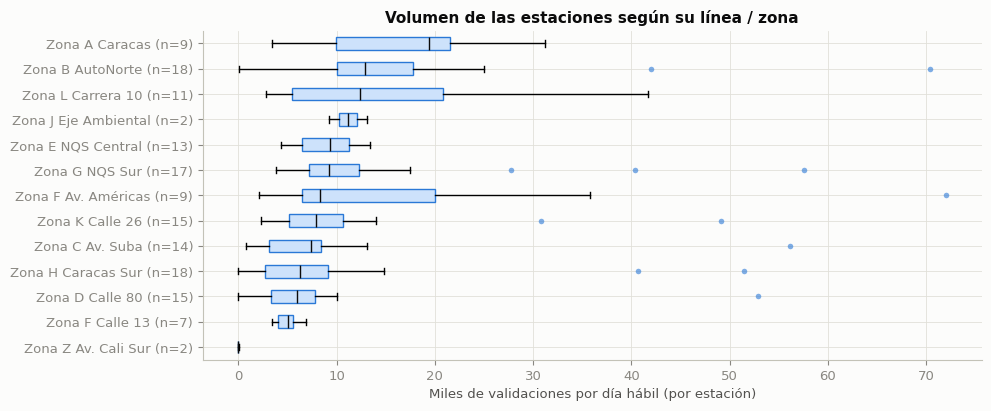

Kruskal-Wallis entre 11 lineas con >=3 estaciones: H=29.6, p=0.0010


In [15]:
orden = est_tab.groupby('linea')['prom_diario_habil'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.2))
datos = [est_tab.loc[est_tab['linea'] == l, 'prom_diario_habil'] / 1000 for l in orden]
ax.boxplot(datos, vert=False, tick_labels=[f"{l} (n={len(d)})" for l, d in zip(orden, datos)],
           showfliers=True, patch_artist=True, boxprops=dict(facecolor='#cde2fb', edgecolor=C['habil']),
           medianprops=dict(color=TINTA), flierprops=dict(marker='o', markersize=4, markerfacecolor=C['habil'],
                                                          markeredgecolor='none', alpha=0.6))
ax.set_xlabel('Miles de validaciones por día hábil (por estación)')
ax.set_title('Volumen de las estaciones según su línea / zona')
plt.tight_layout(); guardar('05_estaciones_por_linea.png'); plt.show()

# Kruskal-Wallis: ¿las medianas de volumen difieren entre lineas? (no parametrico: la variable es muy sesgada)
grupos = [g for g in datos if len(g) >= 3]
H, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis entre {len(grupos)} lineas con >=3 estaciones: H={H:.1f}, p={p:.4f}")

**Lectura — la estación es, por sí sola, la variable que más explica:**
- La mediana es ~8,200 validaciones por día hábil, pero el top (Portal Américas, Portal Norte) supera las **70,000** — 9 veces más. Los 10 primeros son portales/cabeceras + **Calle 100-Marketmedios** (único "no portal" del top 10, consistente con el notebook 02).
- **Línea/zona:** las medianas de volumen sí difieren entre líneas (**Kruskal-Wallis p = 0.001**; se usa esta prueba no paramétrica porque la variable es muy sesgada), pero los rangos dentro de cada línea se traslapan mucho. La línea aporta poco una vez se conoce la estación (lo confirma la importancia casi nula de `linea_cat` en la sección 9). Útil para **reportar** en Grafana (filtro por troncal), no tanto para predecir.

### 5.4 La combinación estación × hora importa: descomposición de la devianza

Un horario puede ser muy activo en una estación y poco activo en otra. Para medir cuánto de la variación de $Y$ explica cada bloque de variables, se usa la **devianza de Poisson** (la medida natural para conteos): para un modelo que asigna a cada celda el promedio de su grupo, el % de devianza explicada funciona como un $R^2$ para conteos.

Se comparan modelos de "promedio por grupo" cada vez más finos, siempre sobre los mismos datos (horas de operación 4–23h).

In [16]:
from sklearn.metrics import mean_poisson_deviance

d = panel[panel['hora'].between(4, 23)].copy()
d['franja_dia'] = np.where(d['tipo_dia'] == 'habil', 'habil', 'no_habil')
dev_nula = mean_poisson_deviance(d['validaciones'], np.full(len(d), d['validaciones'].mean()))

def dev_explicada(claves):
    pred = d.groupby(claves)['validaciones'].transform('mean').clip(lower=1e-6)
    return 1 - mean_poisson_deviance(d['validaciones'], pred) / dev_nula

bloques = {
    'Solo hora': ['hora'],
    'Solo tipo de día (hábil / no hábil)': ['franja_dia'],
    'Solo estación': ['cod_estacion'],
    'Hora × tipo de día': ['hora', 'franja_dia'],
    'Estación + forma horaria común (aprox. aditiva)': None,
    'Estación × hora': ['cod_estacion', 'hora'],
    'Estación × hora × tipo de día': ['cod_estacion', 'hora', 'franja_dia'],
}
# Modelo aditivo (multiplicativo en la escala original): nivel de la estacion x forma horaria del sistema
nivel = d.groupby('cod_estacion')['validaciones'].transform('mean')
forma = d.groupby(['hora', 'franja_dia'])['validaciones'].transform('mean') / d['validaciones'].mean()
dev_aditivo = 1 - mean_poisson_deviance(d['validaciones'], (nivel * forma).clip(lower=1e-6)) / dev_nula

filas = []
for nombre_b, claves in bloques.items():
    filas.append({'modelo (promedio por grupo)': nombre_b,
                  '% devianza explicada': round((dev_aditivo if claves is None else dev_explicada(claves)) * 100, 1)})
descomp = pd.DataFrame(filas)
descomp

,modelo (promedio por grupo),% devianza explicada
0,Solo hora,22.8
1,Solo tipo de día (hábil / no hábil),7.0
2,Solo estación,46.9
3,Hora × tipo de día,30.6
4,Estación + forma horaria común (aprox. aditiva),77.5
5,Estación × hora,89.5
6,Estación × hora × tipo de día,98.4


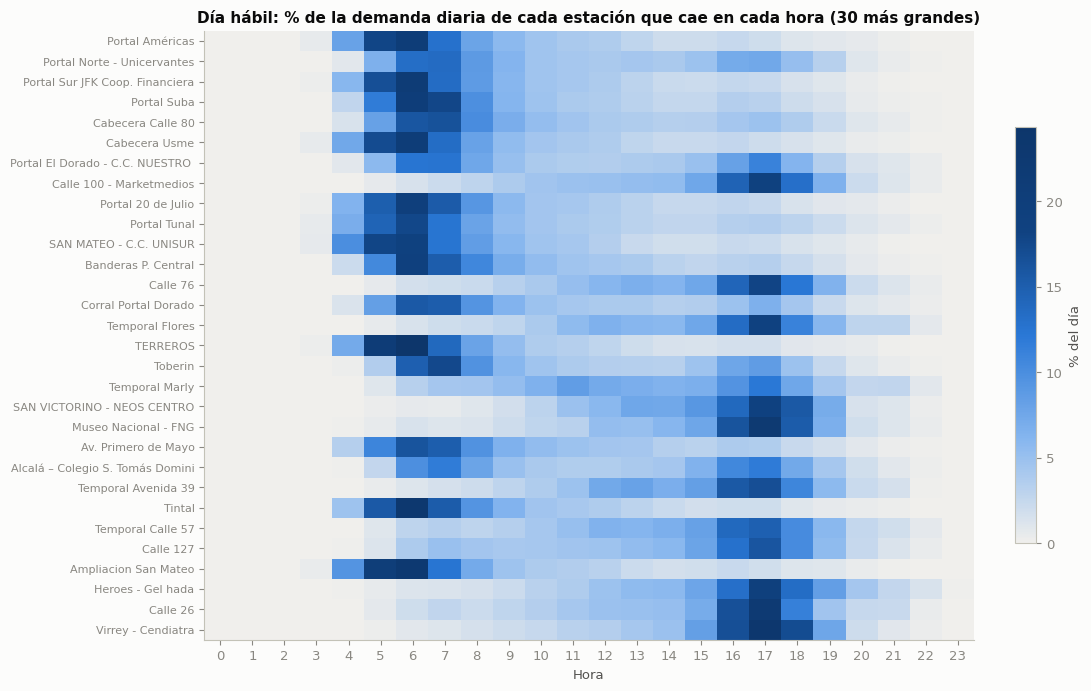

In [17]:
# Heatmap: forma horaria (normalizada) de las 30 estaciones mas grandes en dia habil
top30 = est_tab.head(30).index
curvas = (hab[hab['cod_estacion'].isin(top30)].groupby(['cod_estacion', 'hora'])['validaciones'].sum()
          .unstack(fill_value=0))
curvas_norm = curvas.div(curvas.sum(axis=1), axis=0).loc[top30]
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(curvas_norm.values * 100, aspect='auto', cmap=SEQ)
ax.set_yticks(range(len(top30))); ax.set_yticklabels([nombres[c][:32] for c in top30], fontsize=8)
ax.set_xticks(range(24)); ax.set_xlabel('Hora'); ax.grid(False)
ax.set_title('Día hábil: % de la demanda diaria de cada estación que cae en cada hora (30 más grandes)')
fig.colorbar(im, ax=ax, label='% del día', fraction=0.025)
plt.tight_layout(); guardar('06_heatmap_estacion_hora.png'); plt.show()

**Lectura — la interacción estación × hora es el hallazgo central de esta sección:**

| Modelo | % devianza explicada |
|---|---|
| Solo hora | 22.8% |
| Solo estación | 46.9% |
| Estación + forma horaria **común** a todas | 77.5% |
| Estación × hora (**cada estación con su propia forma**) | 89.5% |
| Estación × hora × tipo de día | **98.4%** |

- Pasar de "todas las estaciones tienen la misma forma horaria" (77.5%) a "cada estación tiene su forma" (89.5%) explica **12 puntos adicionales**: confirma que **un horario puede ser muy activo en una estación y poco activo en otra**.
- Agregar el tipo de día a esa combinación lleva a **98.4%**: lo que queda sin explicar (1.6%) es la variación día a día dentro de un mismo tipo de día — justamente lo que el pronóstico tiene que anticipar y lo que la detección de anomalías tiene que vigilar.
- El heatmap lo hace visible: los portales concentran su día en la madrugada-mañana (Portal Américas: ~21% de su día hábil solo en la hora de las 6 a. m.), mientras estaciones de destino como Calle 100-Marketmedios lo concentran en las 4–6 p. m.

## 6. Variables históricas: ¿la actividad pasada se relaciona con la de hoy?

**Regla de oro para predecir mañana: toda variable debe estar disponible hoy.** Por eso solo se usan valores de **fechas anteriores**:

| Variable | Definición (para la estación $s$, fecha $d$, hora $h$) |
|---|---|
| `lag_1d` | $Y_{s,d-1,h}$: mismo hora, día calendario anterior |
| `lag_7d` | $Y_{s,d-7,h}$: misma hora, mismo día de la semana anterior |
| `ultimo_comparable` | Valor de la última fecha **del mismo grupo de día** (hábil / sábado / domingo-festivo) |
| `prom_comparable` | Promedio de **todas** las fechas anteriores del mismo grupo (nivel habitual) |
| `std_comparable` | Desviación estándar de esas fechas anteriores (variabilidad histórica) |

El festivo se agrupa con el domingo: el notebook 02 mostró que el 7 de agosto se comportó como un domingo.

In [18]:
panel = panel.sort_values(['cod_estacion', 'hora', 'fecha']).reset_index(drop=True)
panel['grupo_dia'] = panel['tipo_dia'].replace({'festivo': 'domingo'})

def lag_calendario(n):
    t = panel[['cod_estacion', 'fecha', 'hora', 'validaciones']].copy()
    t['fecha'] = t['fecha'] + pd.Timedelta(days=n)
    return panel[['cod_estacion', 'fecha', 'hora']].merge(t, how='left')['validaciones'].values

panel['lag_1d'] = lag_calendario(1)
panel['lag_7d'] = lag_calendario(7)

g = panel.sort_values('fecha').groupby(['cod_estacion', 'hora', 'grupo_dia'])['validaciones']
panel = panel.loc[panel.sort_values('fecha').index]
cnt = g.cumcount()                                   # nº de fechas comparables anteriores
s1 = g.cumsum() - panel['validaciones']              # suma de las anteriores (sin la actual)
s2 = (panel['validaciones'] ** 2).groupby([panel['cod_estacion'], panel['hora'], panel['grupo_dia']]).cumsum() - panel['validaciones'] ** 2
panel['n_comparables'] = cnt
panel['ultimo_comparable'] = g.shift(1)
panel['prom_comparable'] = (s1 / cnt).where(cnt > 0)
panel['std_comparable'] = np.sqrt(((s2 - s1 ** 2 / cnt) / (cnt - 1)).clip(lower=0)).where(cnt > 1)
panel = panel.sort_values(['cod_estacion', 'fecha', 'hora']).reset_index(drop=True)

# Verificacion puntual de que no hay fuga de informacion: el promedio comparable de una celda
# se recalcula a mano con fechas estrictamente anteriores
fila = panel[(panel['n_comparables'] >= 3) & (panel['hora'] == 7)].iloc[0]
a_mano = panel[(panel['cod_estacion'] == fila['cod_estacion']) & (panel['hora'] == 7) &
               (panel['grupo_dia'] == fila['grupo_dia']) & (panel['fecha'] < fila['fecha'])]['validaciones'].mean()
assert np.isclose(a_mano, fila['prom_comparable'])
print('Chequeo sin fuga de informacion: OK')
cols_hist = ['lag_1d', 'lag_7d', 'ultimo_comparable', 'prom_comparable', 'std_comparable']
panel.loc[panel['hora'] == 7, ['nombre', 'fecha', 'dia_semana', 'hora', 'validaciones'] + cols_hist].dropna().head(6)

Chequeo sin fuga de informacion: OK


,nombre,fecha,dia_semana,hora,validaciones,lag_1d,lag_7d,ultimo_comparable,prom_comparable,std_comparable
175,Portal Norte - Unicervantes,2026-08-10,lun,7,9058,1529.0,9362.0,9113.0,9550.000000,377.520860
199,Portal Norte - Unicervantes,2026-08-11,mar,7,9364,9058.0,9917.0,9058.0,9451.600000,394.086666
223,Portal Norte - Unicervantes,2026-08-12,mie,7,9956,9364.0,9808.0,9364.0,9437.000000,354.291405
247,Portal Norte - Unicervantes,2026-08-13,jue,7,9515,9956.0,9113.0,9956.0,9511.142857,378.262003
439,Centro Comercial Santa Fe,2026-08-10,lun,7,1134,82.0,1323.0,1194.0,1312.250000,81.434534
463,Centro Comercial Santa Fe,2026-08-11,mar,7,1301,1134.0,1369.0,1134.0,1276.600000,106.434487


In [19]:
# Correlaciones con el objetivo (variables numericas): Pearson (lineal) y Spearman (monotona, robusta al sesgo)
op = panel[panel['hora'].between(4, 23)]
filas = []
for v in cols_hist:
    for etiqueta, sub in [('todas las fechas', op), ('solo dias habiles', op[op['tipo_dia'] == 'habil'])]:
        x = sub[[v, 'validaciones']].dropna()
        filas.append({'variable': v, 'subconjunto': etiqueta, 'n': len(x),
                      'pearson': round(x[v].corr(x['validaciones']), 3),
                      'spearman': round(x[v].corr(x['validaciones'], method='spearman'), 3)})
corr_hist = pd.DataFrame(filas).pivot(index='variable', columns='subconjunto', values=['pearson', 'spearman', 'n'])
corr_hist.loc[cols_hist]

pearson                           spearman                                  n                 
subconjunto       solo dias habiles todas las fechas solo dias habiles todas las fechas solo dias habiles todas las fechas
variable                                                                                                                  
lag_1d                        0.939            0.880             0.941            0.883           21000.0          30000.0
lag_7d                        0.995            0.995             0.991            0.991           12000.0          12000.0
ultimo_comparable             0.995            0.995             0.991            0.990           21000.0          24000.0
prom_comparable               0.996            0.996             0.993            0.991           21000.0          24000.0
std_comparable                0.639            0.639             0.807            0.807           18000.0          18000.0

In [20]:
# lag_1d depende de si el dia anterior es comparable: lunes (ayer=domingo) vs martes-viernes (ayer=habil)
op_h = op[op['tipo_dia'] == 'habil'].dropna(subset=['lag_1d'])
ayer_tipo = op_h['fecha'].sub(pd.Timedelta(days=1)).map(panel.drop_duplicates('fecha').set_index('fecha')['tipo_dia'])
for etiqueta, m in [('ayer fue habil', ayer_tipo == 'habil'), ('ayer NO fue habil (lunes / post-festivo)', ayer_tipo != 'habil')]:
    x = op_h[m]
    print(f"{etiqueta:42s} n={len(x):>6,}  spearman(lag_1d, Y)={x['lag_1d'].corr(x['validaciones'], method='spearman'):.3f}"
          f"  error tipico |Y - lag_1d| = {(x['validaciones'] - x['lag_1d']).abs().median():.0f}")

ayer fue habil                             n=18,000  spearman(lag_1d, Y)=0.992  error tipico |Y - lag_1d| = 19


ayer NO fue habil (lunes / post-festivo)   n= 3,000  spearman(lag_1d, Y)=0.857  error tipico |Y - lag_1d| = 149


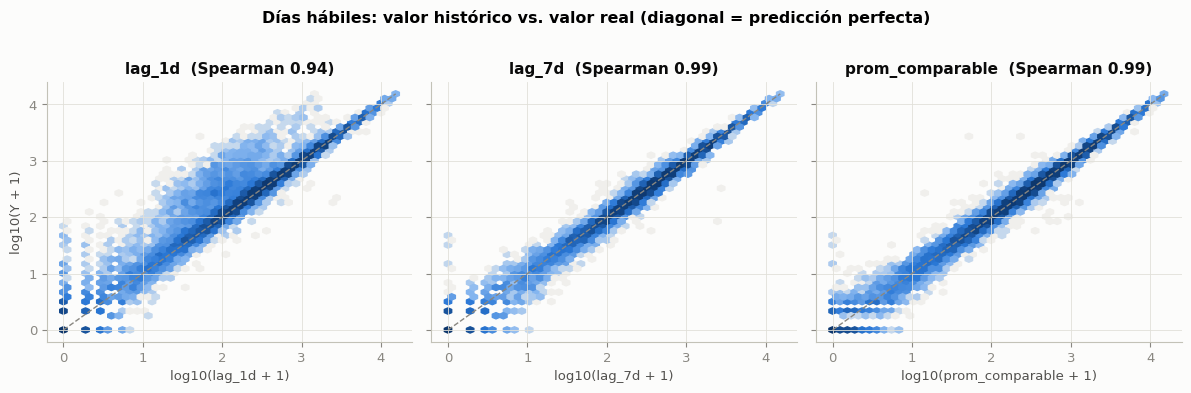

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, v in zip(axes, ['lag_1d', 'lag_7d', 'prom_comparable']):
    x = op_h[[v, 'validaciones']].dropna()
    hb = ax.hexbin(np.log10(x[v] + 1), np.log10(x['validaciones'] + 1), gridsize=45, cmap=SEQ, mincnt=1, bins='log')
    lim = [0, np.log10(op['validaciones'].max() + 1)]
    ax.plot(lim, lim, color=GRIS, lw=1, ls='--')
    ax.set_title(f"{v}  (Spearman {x[v].corr(x['validaciones'], method='spearman'):.2f})")
    ax.set_xlabel(f'log10({v} + 1)')
axes[0].set_ylabel('log10(Y + 1)')
fig.suptitle('Días hábiles: valor histórico vs. valor real (diagonal = predicción perfecta)', y=1.02, fontweight='bold')
plt.tight_layout(); guardar('07_historico_vs_real.png'); plt.show()

**Lectura — la actividad histórica está extremadamente relacionada con la actual:**
- `prom_comparable`, `ultimo_comparable` y `lag_7d`: **Pearson ≈ 0.995, Spearman ≈ 0.99** con el valor real. El sistema es muy repetitivo de un día hábil a otro.
- `lag_1d` (ayer, sin importar qué día fue) es más débil (0.88) — y la razón es concreta: **cuando ayer fue un día comparable, Spearman = 0.992 y el error típico es de 19 validaciones; cuando ayer fue domingo o festivo (lunes, post-festivo), cae a 0.857 y el error típico sube a 149**. Conclusión: **el "día anterior" sirve solo si es un día comparable**; por eso se proponen las variables "último comparable" y "promedio comparable".
- `std_comparable` (variabilidad histórica) correlaciona 0.64–0.81, pero sobre todo porque las estaciones grandes varían más en número absoluto. Es más útil como **medida de incertidumbre** (para alertas: "esto se sale de lo habitual") que como predictor.
- **Ojo:** correlación de 0.99 no significa que haya relación causal: significa que la mejor predicción de una estación-hora es su propio pasado.

## 7. Qué aprovechar de las demás columnas

| Columnas | Uso propuesto | Decisión para el primer modelo |
|---|---|---|
| `Acceso_Estacion` | Cómo se reparte la actividad entre entradas de una misma estación | Descriptivo (7.1) |
| `Dispositivo` | Distribución de registros, posibles problemas de captura | Descriptivo (7.2); **no** equivale a capacidad |
| `Nombre_Perfil`, `Tipo_Tarjeta` | Diferencias de uso por categoría de usuario | Descriptivo (7.3); como variable, solo la **composición histórica** |
| `Valor`, `Tipo_Tarifa` | Análisis tarifario / transbordos | Sección 3; complementario |
| `Numero_Tarjeta` | No necesario para un modelo agregado; tarjetas ≠ personas | Fuera |
| `Saldo_Previo…`, `Saldo_Despues…` | — | Fuera (alcance sencillo) |
| `Ruta`, `ID_Vehiculo`, `Tipo_Vehiculo` | 100% vacías en troncal (confirmado en notebook 01) | Fuera |

### 7.1 Accesos dentro de cada estación

In [22]:
acceso = leer('acceso')
acceso = acceso[acceso['fecha'].isin(FECHAS)]
acceso['acceso'] = acceso['Acceso_Estacion']
acc = acceso.groupby(['cod_estacion', 'acceso'])['n'].sum().reset_index()
acc['participacion'] = acc['n'] / acc.groupby('cod_estacion')['n'].transform('sum')
acc['es_alimentacion'] = acc['acceso'].str.contains(r'ALIMENTAC|DESALIMENTAC', case=False, regex=True)

por_est = acc.groupby('cod_estacion').agg(n_accesos=('acceso', 'nunique'), total=('n', 'sum'),
                                          pct_acceso_principal=('participacion', 'max'))
por_est['pct_desde_alimentacion'] = (acc[acc['es_alimentacion']].groupby('cod_estacion')['n'].sum()
                                     .reindex(por_est.index, fill_value=0) / por_est['total'])
por_est['nombre'] = por_est.index.map(nombres)
print(por_est['n_accesos'].describe().round(1).to_dict())
print(f"Estaciones con 1 solo acceso: {(por_est['n_accesos'] == 1).sum()} de {len(por_est)}")
(por_est.sort_values('total', ascending=False).head(12)
 [['nombre', 'n_accesos', 'pct_acceso_principal', 'pct_desde_alimentacion', 'total']]
 .style.format({'pct_acceso_principal': '{:.0%}', 'pct_desde_alimentacion': '{:.0%}', 'total': '{:,.0f}'}))

{'count': 150.0, 'mean': 3.8, 'std': 3.2, 'min': 1.0, '25%': 2.0, '50%': 2.0, '75%': 4.0, 'max': 20.0}
Estaciones con 1 solo acceso: 3 de 150


,nombre,n_accesos,pct_acceso_principal,pct_desde_alimentacion,total
cod_estacion,,,,,
05000,Portal Américas,16,34%,66%,"670,534"
02000,Portal Norte - Unicervantes,20,33%,51%,"663,576"
07000,Portal Sur JFK Coop. Financiera,15,30%,75%,"539,752"
03000,Portal Suba,12,43%,75%,"526,799"
04000,Cabecera Calle 80,17,35%,65%,"492,337"
09000,Cabecera Usme,10,33%,68%,"481,366"
06000,Portal El Dorado - C.C. NUESTRO BOGOTA,11,31%,60%,"447,471"
10000,Portal 20 de Julio,8,62%,63%,"395,832"
08000,Portal Tunal,14,36%,84%,"387,193"


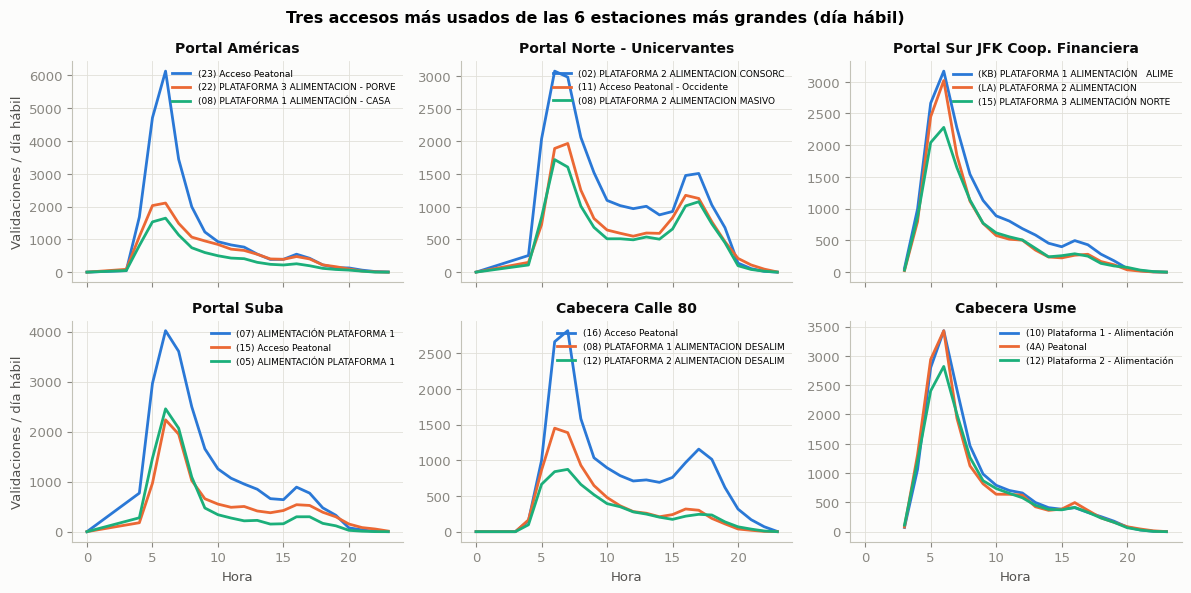

In [23]:
# ¿El acceso mas cargado de cada estacion grande lo es a la misma hora que la estacion?
grandes = por_est.sort_values('total', ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
hab_fechas = panel.loc[panel['tipo_dia'] == 'habil', 'fecha'].unique()
for ax, cod in zip(axes.flat, grandes):
    sub = acceso[(acceso['cod_estacion'] == cod) & acceso['fecha'].isin(hab_fechas)]
    top_acc = sub.groupby('acceso')['n'].sum().nlargest(3).index
    serie = sub[sub['acceso'].isin(top_acc)].groupby(['hora', 'acceso'])['n'].sum().unstack(fill_value=0) / len(hab_fechas)
    for i, a in enumerate(top_acc):
        ax.plot(serie.index, serie[a], color=['#2a78d6', '#eb6834', '#1baf7a'][i], label=a[:38])
    ax.set_title(nombres[cod][:34], fontsize=10); ax.legend(fontsize=6.5, loc='upper right')
for ax in axes[1]: ax.set_xlabel('Hora')
for ax in axes[:, 0]: ax.set_ylabel('Validaciones / día hábil')
fig.suptitle('Tres accesos más usados de las 6 estaciones más grandes (día hábil)', fontweight='bold')
plt.tight_layout(); guardar('08_accesos_estaciones_grandes.png'); plt.show()

**Lectura — accesos: hallazgo operativo directo para la pregunta 5 (dónde ubicar personal de apoyo para gestión de filas):**
- En la **mayoría de estaciones** el acceso principal concentra prácticamente todo (mediana 99%): son estaciones de una sola entrada efectiva.
- En los **portales** la cosa cambia: entre el **51% y el 75% de las validaciones entra por plataformas de alimentación**, no por el acceso peatonal. Ejemplos: Portal Sur JFK y Portal Suba 75%, Cabecera Usme 68%, Portal Américas 66%, Portal 20 de Julio 63% (un solo acceso de alimentación concentra el 62% de toda la estación).
- **Implicación:** si se asigna personal de apoyo para filas y orden en un portal, **mirar solo el acceso peatonal sería un error**; la presión real de la mañana está en las plataformas de alimentación. Esto no se ve agregando por estación: requiere `Acceso_Estacion`.

### 7.2 Dispositivos (validadores)

In [24]:
disp = leer('dispositivo')
disp = disp[disp['fecha'].isin(FECHAS)]
disp_est = disp.groupby('cod_estacion').agg(n_dispositivos=('Dispositivo', 'nunique'), total=('n', 'sum'))
disp_dia = disp.groupby(['Dispositivo', 'fecha'])['n'].sum()
print(f"Dispositivos distintos: {disp['Dispositivo'].nunique():,}")
print(f"Validaciones por dispositivo-dia: mediana={disp_dia.median():.0f}, p90={disp_dia.quantile(.9):.0f}, max={disp_dia.max():,}")
rho, p = stats.spearmanr(disp_est['n_dispositivos'], disp_est['total'])
print(f"Spearman(nº dispositivos, demanda total) entre estaciones = {rho:.2f} (p={p:.1e})")
# Dispositivos que aparecen en mas de una estacion (posible reasignacion o error de captura)
multi = disp.groupby('Dispositivo')['cod_estacion'].nunique()
print(f"Dispositivos registrados en mas de una estacion: {(multi > 1).sum()} ({(multi > 1).mean() * 100:.1f}%)")
# Dias en que un dispositivo habitual de la estacion no registra nada (huecos de captura)
activo = disp.groupby(['cod_estacion', 'Dispositivo'])['fecha'].nunique()
print(f"Dispositivo-estacion activos en todas las {len(FECHAS)} fechas: {(activo == len(FECHAS)).mean() * 100:.1f}%")

Dispositivos distintos: 1,464
Validaciones por dispositivo-dia: mediana=657, p90=2916, max=7,764
Spearman(nº dispositivos, demanda total) entre estaciones = 0.65 (p=2.3e-19)
Dispositivos registrados en mas de una estacion: 0 (0.0%)
Dispositivo-estacion activos en todas las 11 fechas: 88.5%


**Lectura — dispositivos (validadores):**
- 1,464 dispositivos; mediana de 657 validaciones por dispositivo-día, máximo 7,764.
- Más dispositivos ↔ más demanda (**Spearman 0.65**), como se espera, pero **no es capacidad**: un torniquete no dice cuántas personas caben en la plataforma ni cuánto tarda la fila.
- **Calidad:** ningún dispositivo aparece en dos estaciones (bien). El **88.5%** de las parejas dispositivo-estación registra actividad en las 11 fechas; el 11.5% restante tiene días sin datos — puede ser un equipo dañado, retirado o con muy poco uso. Vale la pena revisar si coincide con caídas atípicas de una estación (8.6) antes de llamarlas "anomalías de demanda".

### 7.3 Perfiles de usuario y tipo de tarjeta

In [25]:
perf = base.groupby('Nombre_Perfil')['n'].sum().sort_values(ascending=False)
print((perf / perf.sum() * 100).round(1).to_string())
print()
print(pd.crosstab(base['Nombre_Perfil'], base['Tipo_Tarjeta'], values=base['n'], aggfunc='sum').fillna(0).astype(int))

Nombre_Perfil
(001) Adulto                          50.4
(001) Anonymous                       29.8
(002) Adulto Mayor                     8.3
(006) Apoyo Ciudadano                  3.9
(009) Apoyo Ciudadano Reexpedición     3.0
(101) Adulto PV                        3.0
(005) Discapacidad                     1.7

Tipo_Tarjeta                        tullave Básica  tullave Plus
Nombre_Perfil                                                   
(001) Adulto                                     0       8469193
(001) Anonymous                            5000100             0
(002) Adulto Mayor                               0       1390852
(005) Discapacidad                               0        279344
(006) Apoyo Ciudadano                            0        659967
(009) Apoyo Ciudadano Reexpedición               0        508306
(101) Adulto PV                                  0        498421


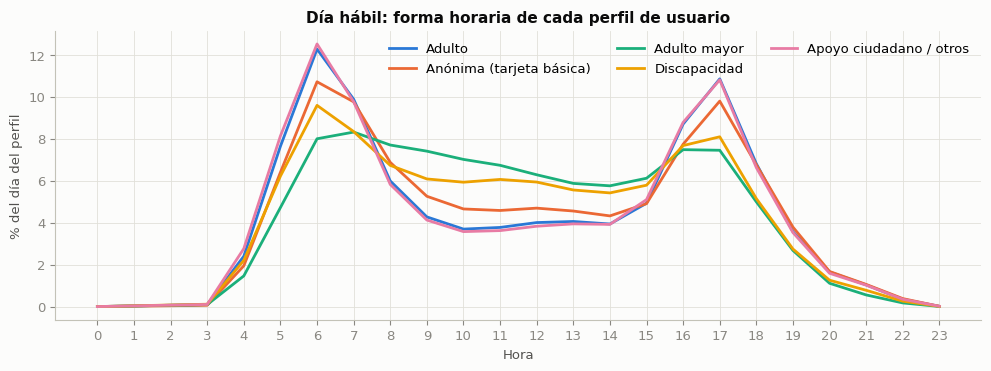

In [26]:
# Composicion por hora en dia habil: ¿los perfiles subsidiados viajan a otras horas?
grupos_perfil = {'(001) Adulto': 'Adulto', '(001) Anonymous': 'Anónima (tarjeta básica)',
                 '(002) Adulto Mayor': 'Adulto mayor', '(005) Discapacidad': 'Discapacidad'}
b_hab = base[base['fecha'].isin(hab_fechas)].copy()
b_hab['grupo'] = b_hab['Nombre_Perfil'].map(grupos_perfil).fillna('Apoyo ciudadano / otros')
comp = b_hab.groupby(['hora', 'grupo'])['n'].sum().unstack(fill_value=0)
comp_norm = comp.div(comp.sum(axis=0), axis=1) * 100   # % del dia de cada perfil que cae en cada hora

fig, ax = plt.subplots(figsize=(10, 3.8))
for i, gname in enumerate(['Adulto', 'Anónima (tarjeta básica)', 'Adulto mayor', 'Discapacidad', 'Apoyo ciudadano / otros']):
    ax.plot(comp_norm.index, comp_norm[gname], color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'][i], label=gname)
ax.set_xticks(range(24)); ax.set_xlabel('Hora'); ax.set_ylabel('% del día del perfil')
ax.set_title('Día hábil: forma horaria de cada perfil de usuario'); ax.legend(ncol=3)
plt.tight_layout(); guardar('09_perfiles_por_hora.png'); plt.show()

**Lectura — perfiles de usuario:**
- Adulto 50.4%, anónima (tullave Básica) 29.8%, adulto mayor 8.3%, apoyo ciudadano 6.9%, Adulto PV 3.0%, discapacidad 1.7%. **`Tipo_Tarjeta` es redundante con el perfil** (Anonymous = Básica; todo lo demás = Plus): basta con una de las dos.
- **Formas horarias distintas:** el **adulto mayor** y **discapacidad** tienen picos mucho más bajos (8% del día en la hora pico frente a 12% del adulto) y viajan más entre 9 a. m. y 3 p. m. (~6–7% por hora frente a ~4%). Su peso relativo sube fuera de la hora pico.
- **Para el modelo:** solo se podría usar la **composición histórica** de perfiles de cada estación (p. ej., "% de adulto mayor en las últimas semanas"), nunca la composición real de mañana, que no se conoce. Se deja como variable candidata de segunda fase.

### 7.4 `Valor` y `Tipo_Tarifa`: ¿qué estaciones son de transbordo?

Con lo visto en la sección 3 (tarifas 2 y 3 = valor 0 = transbordo), el % de validaciones con tarifa distinta de 1 en cada estación indica qué tanto funciona como **punto de transbordo**.

In [27]:
total_est = base.groupby('cod_estacion')['n'].sum()
transb = pd.DataFrame({'nombre': nombres,
                       'pct_transbordo': base[base['Tipo_Tarifa'] != '1,0'].groupby('cod_estacion')['n'].sum() / total_est,
                       'total': total_est}).dropna(subset=['total']).fillna({'pct_transbordo': 0})
transb = transb[transb['total'] >= 20000]
print(transb['pct_transbordo'].describe().round(3).to_dict())
print('\nMayor % de transbordo:')
print(transb.nlargest(8, 'pct_transbordo').round(3).to_string())
print('\nMenor % de transbordo:')
print(transb.nsmallest(5, 'pct_transbordo').round(3).to_string())

{'count': 139.0, 'mean': 0.127, 'std': 0.124, 'min': 0.0, '25%': 0.037, '50%': 0.087, '75%': 0.187, 'max': 0.567}

Mayor % de transbordo:
                                              nombre  pct_transbordo   total
cod_estacion                                                                
10002                            Av. Primero de Mayo           0.567  189993
10001                                    Country Sur           0.556  124501
04003                         Avenida Ciudad de Cali           0.541   80340
07101                                     CASTELLANA           0.531   55151
50008                           Corral Portal Dorado           0.483  286490
07006                              General Santander           0.429   75590
04100                                     Carrera 77           0.394   55510
06000         Portal El Dorado - C.C. NUESTRO BOGOTA           0.372  447471

Menor % de transbordo:
                               nombre  pct_transbordo   total
cod_es

**Lectura — transbordo por estación:**
- La mediana es ~9%, pero hay estaciones donde **más de la mitad** de las validaciones son transbordos: **Av. Primero de Mayo (57%), Country Sur (56%), Avenida Ciudad de Cali (54%) y Castellana (53%)**; Portal El Dorado llega a 37%. Son nodos de integración (con alimentadores/zonal o con otras troncales).
- En el otro extremo, las estaciones de **Soacha (San Mateo, Ampliación San Mateo, Terreros, León XIII) tienen 0% de transbordo**, con volúmenes altos. Es coherente con que la extensión a Soacha tiene un esquema tarifario/de integración distinto, pero **hay que confirmarlo con TransMilenio** antes de afirmarlo en el documento.
- Curiosidad de calidad: el "Corral Portal Dorado" (registrado como corral de bicicletas en el notebook 02) tiene 286 mil validaciones y 48% de transbordo — parece un punto de acceso real del portal codificado aparte, no un corral. Otra pregunta para el diccionario.
- Esto refuerza la decisión de la sección 3: excluir el valor 0 habría quitado más de la mitad de la demanda real en esos puntos.
- `pct_transbordo` es una **variable candidata para el Nivel 1 (perfiles) del notebook 04** (separa "estación de transbordo" de "estación de origen/destino"), complementaria a `razon_am_pm`.

## 8. Siete insights concretos

### 8.1 ¿Qué estaciones concentran la actividad y en qué horarios?

In [28]:
celdas = (hab.groupby(['cod_estacion', 'hora'])['validaciones'].mean().rename('prom_habil')
          .sort_values(ascending=False).reset_index())
celdas['nombre'] = celdas['cod_estacion'].map(nombres)
celdas['% acumulado'] = celdas['prom_habil'].cumsum() / celdas['prom_habil'].sum() * 100
n = len(celdas)
for frac in [0.01, 0.05, 0.10, 0.20]:
    k = int(round(n * frac))
    print(f"El {frac:>4.0%} de las celdas estacion-hora ({k:>4} de {n}) concentra el "
          f"{celdas['prom_habil'].head(k).sum() / celdas['prom_habil'].sum() * 100:.1f}% de las validaciones de un dia habil")
celdas.head(15)[['nombre', 'hora', 'prom_habil', '% acumulado']].round(1)

El   1% de las celdas estacion-hora (  36 de 3600) concentra el 15.5% de las validaciones de un dia habil
El   5% de las celdas estacion-hora ( 180 de 3600) concentra el 39.4% de las validaciones de un dia habil
El  10% de las celdas estacion-hora ( 360 de 3600) concentra el 55.1% de las validaciones de un dia habil
El  20% de las celdas estacion-hora ( 720 de 3600) concentra el 72.9% de las validaciones de un dia habil


,nombre,hora,prom_habil,% acumulado
0,Portal Américas,6,14854.9,0.8
1,Portal Américas,5,12861.4,1.5
2,Portal Sur JFK Coop. Financiera,6,12100.9,2.2
3,Portal Suba,6,11452.5,2.8
4,Cabecera Usme,6,10520.2,3.4
5,Portal Suba,7,9943.1,3.9
6,Portal Sur JFK Coop. Financiera,5,9579.8,4.4
7,Portal Norte - Unicervantes,7,9511.6,4.9
8,Portal Norte - Unicervantes,6,9315.1,5.4
9,Portal Américas,7,9274.6,6.0


**Lectura — concentración en el espacio y el tiempo:**
- En un día hábil, **el 5% de las celdas estación-hora (180 de 3,600) concentra el 39.4% de todas las validaciones**, y el 20% concentra el 72.9%.
- Las 15 celdas más cargadas son, casi todas, **portales entre las 5 y las 7 a. m.** (Portal Américas a las 6 a. m.: 14,855 validaciones en una hora). La única excepción en el top 15 es **Calle 100-Marketmedios a las 5 p. m.**
- **Implicación para la pregunta 5:** esto es precisamente el argumento contra "personal fijo todo el día en todas las estaciones": la presión está en unas pocas estaciones durante unas pocas horas.

### 8.2 ¿Cuánto cambia el volumen entre tipos de día?

In [29]:
tot_tipo = panel.groupby(['cod_estacion', 'tipo_dia', 'fecha'])['validaciones'].sum().groupby(['cod_estacion', 'tipo_dia']).mean().unstack()
tot_tipo['nombre'] = tot_tipo.index.map(nombres)
for t in ['sabado', 'domingo', 'festivo']:
    if t in tot_tipo:
        tot_tipo[f'{t}/habil'] = tot_tipo[t] / tot_tipo['habil']
sistema = panel.groupby(['tipo_dia', 'fecha'])['validaciones'].sum().groupby('tipo_dia').mean()
print('Sistema completo, relacion con un dia habil promedio:')
print((sistema / sistema['habil']).round(2).to_string())
tot_tipo = tot_tipo[tot_tipo['habil'] >= 2000]   # se excluyen estaciones casi vacias (razones inestables)
print(f"\nEstaciones con >=2.000 validaciones/dia habil: {len(tot_tipo)}")
print('Las que MENOS caen el domingo (vida propia el fin de semana):')
print(tot_tipo.sort_values('domingo/habil', ascending=False).head(6)[['nombre', 'habil', 'domingo', 'domingo/habil']].round(2).to_string())
print('\nLas que MAS caen el domingo (puro commuting):')
print(tot_tipo.sort_values('domingo/habil').head(6)[['nombre', 'habil', 'domingo', 'domingo/habil']].round(2).to_string())

Sistema completo, relacion con un dia habil promedio:
tipo_dia
domingo    0.28
festivo    0.29
habil      1.00
sabado     0.58

Estaciones con >=2.000 validaciones/dia habil: 141
Las que MENOS caen el domingo (vida propia el fin de semana):
tipo_dia                                      nombre    habil  domingo  domingo/habil
cod_estacion                                                                         
07007                       Cl38A sur - CENTRO MAYOR  6747.00   4708.0           0.70
09002                                       Consuelo  2981.88   1696.0           0.57
09128         Temporal AV Jimenez - Inter Electricas  9928.50   5578.0           0.56
09110                  AV Jimenez - Inter Electricas  9537.38   5075.0           0.53
08001                                Parque el Tunal  2450.75   1182.0           0.48
09005                                        Danubio  6595.88   3116.0           0.47

Las que MAS caen el domingo (puro commuting):
tipo_dia                

**Lectura — cambio entre tipos de día:**
- Sistema completo: sábado 0.58, domingo 0.28, festivo 0.29 de un día hábil.
- **Pero no todas las estaciones caen igual:** Cl38A Sur–Centro Mayor (centro comercial) conserva el **70%** de su demanda el domingo; Consuelo, Av. Jiménez, Parque El Tunal y Danubio conservan ~50%. En el otro extremo, Castellana, CDS–Carrera 32, Gobernación, Calle 106 y Virrey caen a **8–10%**: son estaciones de oficina/empleo casi exclusivamente de lunes a viernes.
- **Implicación:** un turno de fin de semana "proporcional" (todos al 28%) sería un error; hay estaciones que el domingo necesitan casi lo mismo que un hábil.

### 8.3 ¿Qué estaciones son estables y cuáles variables?

Coeficiente de variación (CV = desviación / media) del total diario **entre días hábiles**, y en las horas pico.

       cv_diario  cv_pico
count    141.000  141.000
mean       0.047    0.051
std        0.038    0.037
min        0.010    0.015
25%        0.025    0.028
50%        0.035    0.040
75%        0.051    0.056
max        0.227    0.215

Spearman(volumen, CV) = -0.26 (p=1.6e-03)


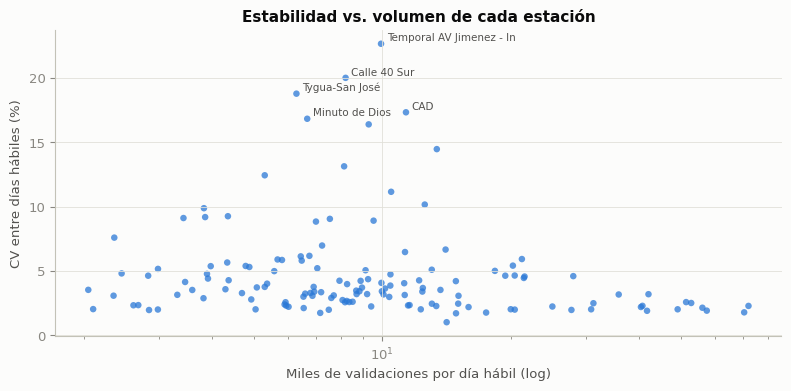


Mas variables:
                                              nombre  prom_diario  cv_diario  cv_pico
cod_estacion                                                                         
09128         Temporal AV Jimenez - Inter Electricas     9928.500      0.227    0.215
09100                                   Calle 40 Sur     8201.500      0.200    0.193
07200                                 Tygua-San José     6291.375      0.188    0.209
07109                                            CAD    11357.375      0.173    0.185
04101                                 Minuto de Dios     6668.250      0.168    0.082
07106                                      EL CAMPIN     9289.000      0.164    0.091

Mas estables:
                                   nombre  prom_diario  cv_diario  cv_pico
cod_estacion                                                              
02502                            Terminal    14143.500      0.010    0.015
09001                             Molinos    14877.125  

In [30]:
diario_hab = hab.groupby(['cod_estacion', 'fecha'])['validaciones'].sum()
pico_hab = hab[hab['hora'].isin(HORAS_PICO)].groupby(['cod_estacion', 'fecha'])['validaciones'].sum()
estab = pd.DataFrame({
    'prom_diario': diario_hab.groupby('cod_estacion').mean(),
    'cv_diario': diario_hab.groupby('cod_estacion').std() / diario_hab.groupby('cod_estacion').mean(),
    'cv_pico': pico_hab.groupby('cod_estacion').std() / pico_hab.groupby('cod_estacion').mean(),
})
estab['nombre'] = estab.index.map(nombres)
estab = estab[estab['prom_diario'] >= 2000]
print(estab[['cv_diario', 'cv_pico']].describe().round(3))
rho, p = stats.spearmanr(estab['prom_diario'], estab['cv_diario'])
print(f"\nSpearman(volumen, CV) = {rho:.2f} (p={p:.1e})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(estab['prom_diario'] / 1000, estab['cv_diario'] * 100, s=22, color=C['habil'], alpha=0.75, edgecolors='none')
for cod, r in estab.nlargest(5, 'cv_diario').iterrows():
    ax.annotate(r['nombre'][:24], (r['prom_diario'] / 1000, r['cv_diario'] * 100), fontsize=7.5, color=TINTA2,
                xytext=(4, 2), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('Miles de validaciones por día hábil (log)')
ax.set_ylabel('CV entre días hábiles (%)'); ax.set_title('Estabilidad vs. volumen de cada estación')
plt.tight_layout(); guardar('10_estabilidad_vs_volumen.png'); plt.show()
print('\nMas variables:'); print(estab.nlargest(6, 'cv_diario')[['nombre', 'prom_diario', 'cv_diario', 'cv_pico']].round(3).to_string())
print('\nMas estables:'); print(estab.nsmallest(6, 'cv_diario')[['nombre', 'prom_diario', 'cv_diario', 'cv_pico']].round(3).to_string())

**Lectura — estabilidad:**
- La gran mayoría de estaciones es **muy estable** entre días hábiles: mediana del CV = **3.5%** (4.0% en horas pico). Esto explica por qué el promedio histórico predice tan bien (sección 9).
- Las estaciones grandes son algo más estables que las pequeñas (Spearman volumen–CV = −0.26). Portal Norte y Portal 20 de Julio varían menos de 2%.
- Las **más variables** (CV 16–23%) tienen explicación operativa, no aleatoria: **Temporal Av. Jiménez** y **Calle 40 Sur** (paraderos temporales por obras, ver notebook 02), **CAD** y **El Campín** (eventos / trámites), **Tygua–San José**. Son exactamente las estaciones donde un pronóstico basado en el promedio fallará y donde haría falta información de contexto (obras, eventos) — punto c de la rúbrica.

### 8.4 ¿Estaciones con distinto volumen comparten perfil horario?

Vista previa (el clustering formal del Nivel 1 está en el notebook 04): K-Means sobre la **curva horaria normalizada** de día hábil (24 valores que suman 1 → elimina el volumen y deja solo la forma).

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

validas = estab.index
curva_hab = hab[hab['cod_estacion'].isin(validas)].groupby(['cod_estacion', 'hora'])['validaciones'].sum().unstack(fill_value=0)
X = curva_hab.div(curva_hab.sum(axis=1), axis=0)
sil = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)) for k in range(2, 8)}
print('Silhouette por k:', {k: round(v, 3) for k, v in sil.items()})
K = 4
km = KMeans(K, n_init=20, random_state=0).fit(X)
perfil = pd.Series(km.labels_, index=X.index, name='perfil')
pico_am = X.loc[:, 5:9].sum(axis=1); pico_pm = X.loc[:, 16:20].sum(axis=1)
resumen_k = pd.DataFrame({'n_estaciones': perfil.value_counts(),
                          'pct_pico_am': pico_am.groupby(perfil).mean(), 'pct_pico_pm': pico_pm.groupby(perfil).mean(),
                          'vol_min': estab['prom_diario'].groupby(perfil).min(),
                          'vol_mediana': estab['prom_diario'].groupby(perfil).median(),
                          'vol_max': estab['prom_diario'].groupby(perfil).max()}).round(2)
resumen_k['ejemplos'] = [', '.join(estab.loc[perfil[perfil == k].index].nlargest(3, 'prom_diario')['nombre'].str[:18]) for k in resumen_k.index]
resumen_k

Silhouette por k: {2: 0.578, 3: 0.482, 4: 0.424, 5: 0.322, 6: 0.307, 7: 0.261}


,n_estaciones,pct_pico_am,pct_pico_pm,vol_min,vol_mediana,vol_max,ejemplos
perfil,,,,,,,
0,23,0.66,0.09,2346.62,13373.88,72028.50,"Portal Américas, Portal Sur JFK Coo, Portal Suba"
1,65,0.13,0.52,2355.88,8959.62,42002.25,"Calle 100 - Market, Calle 76, Temporal Flores"
2,24,0.36,0.34,2047.62,7028.06,49158.12,"Portal El Dorado -, Alcalá – Colegio S, Restrepo"
3,29,0.53,0.19,2102.00,8067.88,70372.88,"Portal Norte - Uni, Cabecera Calle 80, Bandera..."


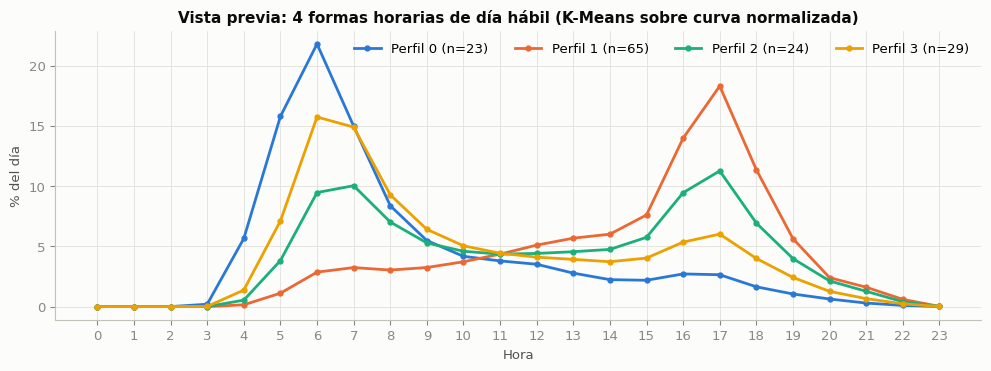

In [32]:
fig, ax = plt.subplots(figsize=(10, 3.8))
cols_k = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
for k in range(K):
    ax.plot(range(24), X[perfil == k].mean() * 100, color=cols_k[k], marker='o', markersize=3.5,
            label=f"Perfil {k} (n={(perfil == k).sum()})")
ax.set_xticks(range(24)); ax.set_xlabel('Hora'); ax.set_ylabel('% del día')
ax.set_title(f'Vista previa: {K} formas horarias de día hábil (K-Means sobre curva normalizada)'); ax.legend(ncol=K)
plt.tight_layout(); guardar('11_perfiles_horarios_preview.png'); plt.show()

**Lectura — sí: estaciones de volumen muy distinto comparten perfil horario:**
- Con solo la forma de la curva (sin volumen), el silhouette es alto con k=2 (0.58) y razonable con k=4 (0.42). La vista previa con k=4 muestra:
  - **Perfil 0 — "residencial / salida AM fuerte"** (23 estaciones, 66% del día en pico AM): Portal Américas, Portal Sur, Portal Suba…
  - **Perfil 3 — "residencial moderado"** (29, 53% AM): Portal Norte, Cabecera Calle 80, Banderas…
  - **Perfil 2 — "mixto / transbordo"** (24, AM ≈ PM): Portal El Dorado, Alcalá, Restrepo…
  - **Perfil 1 — "destino / salida PM"** (65, 52% PM): Calle 100, Calle 76, Temporal Flores…
- **En cada perfil conviven estaciones de ~2,000 y de 40,000–70,000 validaciones diarias.** El volumen y la forma son dimensiones distintas → el clustering del Nivel 1 (notebook 04) debe tratarlas por separado (forma normalizada + `log(demanda_total)`), tal como propuso el notebook 02.

### 8.5 ¿Qué accesos concentran la actividad dentro de cada estación?

Ver sección 7.1 (tabla de participación del acceso principal y de los accesos de alimentación).

### 8.6 ¿Qué fechas se apartan del patrón habitual?

Para cada estación-fecha se compara el total del día contra el promedio de los **otros** días de su mismo grupo (hábil / sábado / domingo-festivo). Se usa una puntuación robusta (desviación relativa).

In [33]:
dia_est = panel.groupby(['cod_estacion', 'fecha', 'grupo_dia', 'tipo_dia'])['validaciones'].sum().reset_index()
grp = dia_est.groupby(['cod_estacion', 'grupo_dia'])['validaciones']
n_g = grp.transform('count')
dia_est['esperado'] = (grp.transform('sum') - dia_est['validaciones']) / (n_g - 1)   # promedio de los OTROS dias
dia_est['desv_rel'] = dia_est['validaciones'] / dia_est['esperado'] - 1
dia_est['nombre'] = dia_est['cod_estacion'].map(nombres)
dia_est = dia_est[(n_g >= 3) & (dia_est['esperado'] >= 2000)]

# Sistema completo
sis = panel.groupby(['fecha', 'grupo_dia', 'tipo_dia'])['validaciones'].sum().reset_index()
gs = sis.groupby('grupo_dia')['validaciones']
sis['esperado_otros'] = (gs.transform('sum') - sis['validaciones']) / (gs.transform('count') - 1)
sis['desv_rel_%'] = ((sis['validaciones'] / sis['esperado_otros'] - 1) * 100).round(1)
print('Sistema completo, desviacion de cada fecha vs. los otros dias de su grupo:')
print(sis.to_string(index=False))
print('\nEstacion-fecha con mayor desviacion (|desv| > 30%):')
atip = dia_est[dia_est['desv_rel'].abs() > 0.30].sort_values('desv_rel', key=abs, ascending=False)
print(f"{len(atip)} casos de {len(dia_est):,} estacion-fecha evaluados")
atip.head(12)[['nombre', 'fecha', 'tipo_dia', 'validaciones', 'esperado', 'desv_rel']].round({'esperado': 0, 'desv_rel': 2})

Sistema completo, desviacion de cada fecha vs. los otros dias de su grupo:
     fecha grupo_dia tipo_dia  validaciones  esperado_otros  desv_rel_%
2026-08-03     habil    habil       1817358    1.840620e+06        -1.3
2026-08-04     habil    habil       1879861    1.831691e+06         2.6
2026-08-05     habil    habil       1893706    1.829713e+06         3.5
2026-08-06     habil    habil       1837051    1.837807e+06        -0.0
2026-08-07   domingo  festivo        525834    5.164470e+05         1.8
2026-08-08    sabado   sabado       1062203             NaN         NaN
2026-08-09   domingo  domingo        516447    5.258340e+05        -1.8
2026-08-10     habil    habil       1751957    1.849963e+06        -5.3
2026-08-11     habil    habil       1832549    1.838450e+06        -0.3
2026-08-12     habil    habil       1852058    1.835663e+06         0.9
2026-08-13     habil    habil       1837159    1.837791e+06        -0.0

Estacion-fecha con mayor desviacion (|desv| > 30%):
5 casos 

,nombre,fecha,tipo_dia,validaciones,esperado,desv_rel
1333,Temporal AV Jimenez - Inter Electricas,2026-08-05,habil,12848,9511.0,0.35
1012,Tygua-San José,2026-08-03,habil,8087,6035.0,0.34
714,Corferias,2026-08-13,habil,6761,5095.0,0.33
1338,Temporal AV Jimenez - Inter Electricas,2026-08-10,habil,7119,10330.0,-0.31
1189,Calle 40 Sur,2026-08-04,habil,10280,7905.0,0.30


**Lectura — fechas que se apartan del patrón:**
- **A nivel sistema, ningún día se aparta mucho:** todos los hábiles están entre −5.3% y +3.5% del promedio de los otros hábiles. El más bajo es el **lunes 10 de agosto (−5.3%)**, primer día después de un puente festivo — un efecto conocido de "regreso".
- **A nivel estación-fecha**, solo **5 de 1,128** casos superan ±30%, y casi todos son estaciones ya señaladas como variables en 8.3 (Temporal Av. Jiménez, Tygua–San José, Calle 40 Sur) más **Corferias el 13 de agosto (+33%)** — probablemente un evento en el recinto ferial. Es el tipo de caso que se cruzaría con un calendario de eventos (punto c).
- Esta tabla es la base de la **tabla `anomalias`** planeada para AWS/Grafana.

## 9. Prueba de concepto: ¿el histórico reciente permite anticipar mañana?

**Insight 8.7.** Se separan las fechas en **entrenamiento** (las primeras) y **prueba** (las últimas 3 fechas disponibles). Todo se evalúa en fechas **posteriores** al entrenamiento: así se simula lo que pasaría en operación real.

Se comparan 4 **referencias sencillas** (lo que un analista haría a mano) contra un **modelo de Machine Learning**:

| Método | Predicción para la estación $s$, fecha $d$, hora $h$ |
|---|---|
| Ayer | $Y_{s,d-1,h}$ |
| Hace 7 días | $Y_{s,d-7,h}$ |
| Último día comparable | Último día del mismo grupo (hábil/sábado/domingo-festivo) |
| Promedio comparable | Promedio de todos los días anteriores del mismo grupo |
| **ML: Gradient Boosting (pérdida Poisson)** | Aprende con hora, día, festivo, estación, línea y las 5 variables históricas |

Métricas: **MAE** (error absoluto medio, en validaciones por hora) y **WAPE** (error absoluto total / validaciones totales; un WAPE de 10% significa que el error suma el 10% del volumen real).

In [34]:
from sklearn.ensemble import HistGradientBoostingRegressor

N_PRUEBA = 3
fechas_ord = sorted(panel['fecha'].unique())
f_prueba = fechas_ord[-N_PRUEBA:]
datos = panel[panel['hora'].between(4, 23)].copy()
datos['est_cat'] = datos['cod_estacion'].astype('category').cat.codes
datos['linea_cat'] = datos['linea'].astype('category').cat.codes
FEATS = ['hora', 'dow', 'festivo', 'est_cat', 'linea_cat'] + cols_hist
CATEG = [False, True, False, True, True] + [False] * len(cols_hist)

train = datos[~datos['fecha'].isin(f_prueba)]
test = datos[datos['fecha'].isin(f_prueba)].copy()
print(f"Entrenamiento: {len(train):,} filas, {train['fecha'].nunique()} fechas ({train['fecha'].min():%d-%b} a {train['fecha'].max():%d-%b})")
print(f"Prueba:        {len(test):,} filas, fechas {[f'{f:%d-%b (%a)}' for f in f_prueba]}")

modelo = HistGradientBoostingRegressor(loss='poisson', max_iter=400, learning_rate=0.06, max_leaf_nodes=63,
                                       categorical_features=CATEG, random_state=0)
t0 = time.time(); modelo.fit(train[FEATS], train['validaciones']); print(f"Entrenado en {time.time() - t0:.1f} s")
test['pred_ML'] = modelo.predict(test[FEATS])

Entrenamiento: 24,000 filas, 8 fechas (03-Aug a 10-Aug)
Prueba:        9,000 filas, fechas ['11-Aug (Tue)', '12-Aug (Wed)', '13-Aug (Thu)']


Entrenado en 7.3 s


In [35]:
metodos = {'Ayer': 'lag_1d', 'Hace 7 días': 'lag_7d', 'Último comparable': 'ultimo_comparable',
           'Promedio comparable': 'prom_comparable', 'ML (Gradient Boosting Poisson)': 'pred_ML'}
# Comparacion justa: solo filas donde TODOS los metodos tienen prediccion
comun = test.dropna(subset=[c for c in metodos.values()])
print(f"Filas de prueba con todos los metodos disponibles: {len(comun):,} de {len(test):,}")

def metricas(df, col):
    e = (df['validaciones'] - df[col]).abs()
    return {'MAE': e.mean(), 'WAPE_%': e.sum() / df['validaciones'].sum() * 100}

filas = []
for nombre_m, col in metodos.items():
    r = {'metodo': nombre_m}
    for etiqueta, sub in [('todas', comun), ('pico', comun[comun['hora'].isin(HORAS_PICO)])]:
        m = metricas(sub, col)
        r[f'MAE {etiqueta}'] = round(m['MAE'], 1); r[f'WAPE % {etiqueta}'] = round(m['WAPE_%'], 1)
    filas.append(r)
tabla_errores = pd.DataFrame(filas).set_index('metodo')
mejor_ref = tabla_errores.drop('ML (Gradient Boosting Poisson)')['WAPE % todas'].idxmin()
mejora = 1 - tabla_errores.loc['ML (Gradient Boosting Poisson)', 'WAPE % todas'] / tabla_errores.loc[mejor_ref, 'WAPE % todas']
if mejora > 0:
    print(f"Mejor referencia sencilla: {mejor_ref}. El modelo ML reduce su WAPE en {mejora * 100:.1f}%.")
else:
    print(f"Mejor referencia sencilla: {mejor_ref}. El modelo ML NO la supera: su WAPE es {-mejora * 100:.1f}% mayor.")
tabla_errores

Filas de prueba con todos los metodos disponibles: 9,000 de 9,000
Mejor referencia sencilla: Promedio comparable. El modelo ML NO la supera: su WAPE es 30.0% mayor.


,MAE todas,WAPE % todas,MAE pico,WAPE % pico
metodo,,,,
Ayer,42.9,7.0,56.2,6.5
Hace 7 días,50.1,8.2,63.9,7.4
Último comparable,42.9,7.0,56.2,6.5
Promedio comparable,36.6,6.0,46.8,5.4
ML (Gradient Boosting Poisson),47.7,7.8,66.2,7.7


In [36]:
# Error por fecha de prueba: ¿el modelo se cae algun dia en particular?
por_dia_err = []
for f in f_prueba:
    sub = comun[comun['fecha'] == f]
    fila = {'fecha': f'{f:%d-%b (%a)}', 'tipo_dia': sub['tipo_dia'].iloc[0]}
    for nombre_m, col in metodos.items():
        fila[nombre_m] = round(metricas(sub, col)['WAPE_%'], 1)
    por_dia_err.append(fila)
pd.DataFrame(por_dia_err).set_index('fecha')

,tipo_dia,Ayer,Hace 7 días,Último comparable,Promedio comparable,ML (Gradient Boosting Poisson)
fecha,,,,,,
11-Aug (Tue),habil,8.5,7.4,8.5,6.1,7.8
12-Aug (Wed),habil,6.0,7.9,6.0,6.0,7.1
13-Aug (Thu),habil,6.5,9.2,6.5,5.9,8.4


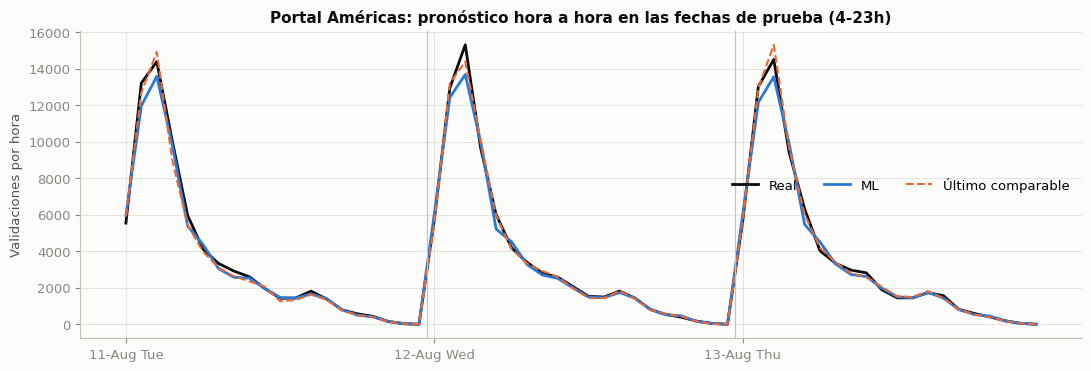

In [37]:
# Ejemplo visual: estacion mas grande, fechas de prueba
cod_ej = est_tab.index[0]
ej = test[test['cod_estacion'] == cod_ej].sort_values(['fecha', 'hora'])
x = np.arange(len(ej))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, ej['validaciones'], color=TINTA, lw=2, label='Real')
ax.plot(x, ej['pred_ML'], color=C['habil'], lw=2, label='ML')
ax.plot(x, ej[ 'ultimo_comparable'], color=C['sabado'], lw=1.5, ls='--', label='Último comparable')
cortes = np.where(ej['hora'].values == 4)[0]
ax.set_xticks(cortes); ax.set_xticklabels([f"{f:%d-%b %a}" for f in ej['fecha'].iloc[cortes]])
for c in cortes[1:]: ax.axvline(c - 0.5, color='#c3c2b7', lw=0.8)
ax.set_ylabel('Validaciones por hora'); ax.legend(ncol=3)
ax.set_title(f'{nombres[cod_ej]}: pronóstico hora a hora en las fechas de prueba (4-23h)')
plt.tight_layout(); guardar('12_pronostico_ejemplo.png'); plt.show()

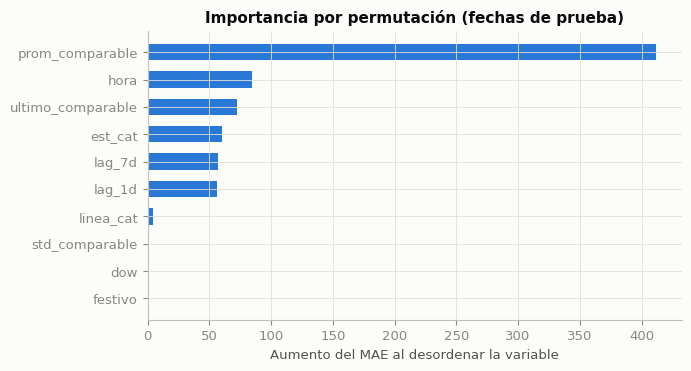

prom_comparable      411.8
hora                  84.9
ultimo_comparable     72.6
est_cat               60.2
lag_7d                56.7
lag_1d                56.1
linea_cat              4.0
std_comparable         0.7
dow                    0.7
festivo                0.0
dtype: float64

In [38]:
# ¿Cuanto aporta cada variable a la prediccion? (importancia por permutacion, en datos de prueba)
from sklearn.inspection import permutation_importance
muestra = test.dropna(subset=['lag_1d']).sample(min(15000, len(test)), random_state=0)
imp = permutation_importance(modelo, muestra[FEATS], muestra['validaciones'], n_repeats=4, random_state=0,
                             scoring='neg_mean_absolute_error')
importancia = pd.Series(imp.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(importancia.index, importancia.values, color=C['habil'], height=0.6)
ax.set_xlabel('Aumento del MAE al desordenar la variable'); ax.set_title('Importancia por permutación (fechas de prueba)')
plt.tight_layout(); guardar('13_importancia_variables.png'); plt.show()
importancia.sort_values(ascending=False).round(1)

**Lectura — el resultado más importante de la propuesta, y es honesto:**

| Método | WAPE (todas las horas) | WAPE (horas pico) |
|---|---|---|
| Ayer / Último comparable | 7.0% | 6.5% |
| Hace 7 días | 8.2% | 7.4% |
| **Promedio de días comparables** | **6.0%** | **5.4%** |
| ML (Gradient Boosting Poisson) | 7.8% | 7.7% |

1. **La actividad del día siguiente sí se puede anticipar bien:** con solo promediar los días hábiles anteriores, a la misma hora y en la misma estación, el error total es de **6%** (5.4% en horas pico). Un responsable de operación podría planear con eso desde hoy.
2. **Con esta historia el modelo de ML NO supera a la referencia sencilla.** Se probó además una variante (entrenar solo con filas que tienen historia y aprender la corrección sobre el promedio) y tampoco la supera (7.5%). No se siguió ajustando para no "hacer trampa" con los 3 días de prueba. La razón es de datos, no de técnica: el modelo se entrena con **8 fechas, de las cuales solo 5 tienen historia previa**, y la variable más importante es justamente el promedio histórico (importancia por permutación muy por encima de las demás).
3. **Qué significa para la decisión del grupo:** la "referencia sencilla" no es un modelo de relleno — **es el estándar que cualquier ML debe superar para justificarse**, exactamente la evaluación técnica del piloto de la sección 11. Con las 3 semanas completas (y mejor aún, con variables de eventos/obras/clima, que es donde el promedio falla: sección 8.3), el ML tiene margen para ganarle; hoy no lo tiene.
4. Explicar y predecir son objetivos distintos: que `prom_comparable` sea la variable más importante no "causa" nada; dice que la mejor información sobre una estación-hora es su propio pasado.

## 10. Cómo encaja con el resto del proyecto

Esta tabla describe la integración completa (corresponde a la **opción C** de la sección 12; las opciones A y B no tocan Prefect, AWS ni Grafana). Reutiliza toda la arquitectura ya planeada; solo agrega 2 tablas de resultados y 2 paneles.

| Componente | Qué hace con esta propuesta | Cambio frente al plan actual |
|---|---|---|
| **Dask** (punto e) | Lee los ZIP y genera `panel` (estación–fecha–hora) — exactamente la función `procesar_archivo` de la sección 2, paralelizada | Ninguno: es la misma agregación |
| **Prefect** (punto d) | Cada archivo nuevo → agrega → recalcula variables históricas → **pronostica el día siguiente** → mide el error del pronóstico de ayer | +2 tareas: `pronosticar_dia_siguiente`, `evaluar_pronostico` |
| **AWS RDS** (punto f) | Guarda solo resultados: `fact_demanda_estacion_hora` (ya planeada), + `pronostico_estacion_hora` y `error_pronostico` | +2 tablas, siguen siendo resultados (nunca el crudo) |
| **Grafana** (punto g) | Patrones (ya planeados) + panel "mañana: estaciones y franjas con mayor actividad prevista" + panel de error real vs. previsto | +2 paneles |
| **Notebook 04** (Nivel 1 perfiles + Nivel 2 prioridad) | Se mantiene igual. El pronóstico solo agrega una columna: `indice_prioridad` **esperado** para mañana, calculado con validaciones previstas en vez de observadas | Ninguno en lo ya hecho; +1 sección opcional |

**Límite honesto:** la salida apoya la **revisión** de recursos operativos (dónde y cuándo mirar). Para decidir **cuántos** empleados asignar se necesitarían datos adicionales de capacidad de las estaciones y tiempos de atención/filas, que este dataset no trae.

## 11. Caso hipotético: cómo se le vendería esto al operador

Si este modelo se ofreciera a TransMilenio, **el producto no es "un modelo de ML"**: es una herramienta para **anticipar actividad y planificar recursos con tiempo**. El modelo es el motor; el servicio responde a una pregunta concreta:

> **"¿Dónde y cuándo debemos revisar la operación mañana?"**

| Beneficio para el cliente | Qué entrega la solución | Cómo comprobar el beneficio |
|---|---|---|
| Planificación anticipada | Volumen esperado por estación y hora para el día siguiente | Anticipación disponible y precisión (WAPE de la sección 9) |
| Priorización de supervisión | Estaciones y franjas con mayor actividad prevista | Utilidad de las prioridades para el equipo operativo |
| Revisión de turnos | Perfiles por horario, día y temporada (secciones 5 y 8) | Recursos programados vs. actividad esperada |
| Detección de cambios | Alertas cuando la actividad se aparta de lo habitual (sección 8.6) | Alertas útiles frente a falsas alarmas |
| Menos trabajo manual | Procesamiento automático de archivos nuevos (Prefect) | Tiempo de planificación antes vs. después |

**Ejemplo:** el sistema anticipa que mañana una estación tendrá un volumen superior al habitual entre 6 y 8 a. m. El responsable revisa la dotación, organiza apoyo y observa el acceso más activo (sección 7.1). Después compara lo previsto con lo ocurrido.

**Cómo se le presentaría:** *"Proponemos convertir sus registros de validaciones en pronósticos por estación y horario. Su equipo podrá identificar anticipadamente las franjas de mayor actividad, revisar los turnos y detectar cambios. Empezaremos con un piloto para comprobar si la herramienta mejora sus estimaciones actuales y aporta valor a decisiones concretas."*

**La conversación comercial empieza con tres preguntas** (determinan qué predecir y cómo medir el éxito):
1. ¿Qué decisión toman hoy? (p. ej., programar personal de apoyo).
2. ¿Con cuánta anticipación necesitan decidir? (un día, una semana, un mes).
3. ¿Qué problema buscan reducir? (tiempo de planificación, desajustes de turnos, tiempos de espera).

**Modelo de negocio:** piloto pagado con estaciones y periodos acordados, con dos evaluaciones — **técnica** (modelo vs. referencia sencilla como el último día comparable; error por estación y horario — exactamente la tabla de la sección 9) y **operativa** (qué decisiones apoyó y si mejoraron los indicadores acordados). Luego, implementación inicial + cuota recurrente por actualización, monitoreo, reentrenamiento y soporte.

**Promesa defendible:** *"mejorar la anticipación y apoyar la planificación"*. Los ahorros, la reducción de filas o la mejora del servicio se convierten en argumentos de venta **solo cuando el piloto los demuestre** — para eso harían falta mediciones operativas que hoy no se tienen.

In [39]:
print('Evidencia tecnica que respaldaria el piloto (calculada arriba, seccion 9):')
print(f"  - Mejor referencia sencilla: '{mejor_ref}' con WAPE = {tabla_errores.loc[mejor_ref, 'WAPE % todas']:.1f}%")
print(f"  - Modelo ML: WAPE = {tabla_errores.loc['ML (Gradient Boosting Poisson)', 'WAPE % todas']:.1f}%  -> "
      + (f"{mejora * 100:.1f}% menos error que la referencia" if mejora > 0
         else f"{-mejora * 100:.1f}% MAS error que la referencia (con esta historia, el ML aun no se justifica)"))
print(f"  - En horas pico: referencia {tabla_errores.loc[mejor_ref, 'WAPE % pico']:.1f}% vs. "
      f"ML {tabla_errores.loc['ML (Gradient Boosting Poisson)', 'WAPE % pico']:.1f}%")

Evidencia tecnica que respaldaria el piloto (calculada arriba, seccion 9):
  - Mejor referencia sencilla: 'Promedio comparable' con WAPE = 6.0%
  - Modelo ML: WAPE = 7.8%  -> 30.0% MAS error que la referencia (con esta historia, el ML aun no se justifica)
  - En horas pico: referencia 5.4% vs. ML 7.7%


---
## 12. Propuesta para votación del grupo

El grupo ya adoptó (1-oct) la pregunta reformulada y el **blueprint de 2 niveles**: Nivel 1 = perfiles por estación (clustering); Nivel 2 = `indice_prioridad` por estación × tipo de día × hora. **Esta propuesta no cambia ese rumbo**; se vota qué incorporar de este notebook.

### Qué se vota

| Opción | Qué cambia en el plan | Esfuerzo extra (hoy 4 oct, presentación 10 oct) |
|---|---|---|
| **A. Solo hallazgos** | Se incorporan al notebook 02/04 las variables y hallazgos nuevos (lista abajo). El pronóstico queda como trabajo futuro, como ya está | Bajo |
| **B. Hallazgos + evaluación temporal (recomendada)** | A, **más** una sección corta en el notebook 04: "¿se puede anticipar la prioridad de mañana?", con la referencia "promedio de días comparables" y su error medido en fechas posteriores | Bajo-medio: el código ya está en este notebook (sección 9) |
| **C. Pronóstico completo en producción** | B, más tareas de Prefect, tablas en RDS y paneles en Grafana para el pronóstico diario | Medio-alto: compite en tiempo con Dask/Prefect/AWS/Grafana |

### Por qué recomiendo la opción B
1. **Responde mejor la pregunta 5 sin cambiar la unidad de análisis**: el Nivel 2 dice *dónde y cuándo* hay presión típica; la evaluación temporal dice *qué tan confiable es planear el turno de mañana con eso* — **error de 6% (5.4% en hora pico)** con solo el promedio de días comparables.
2. **Da evidencia de evaluación con fechas futuras**, algo que el profesor puede preguntar y que un ranking o un clustering por sí solos no ofrecen.
3. **Es defendible aunque el ML no gane:** "el promedio comparable anticipa con ~6% de error; el ML todavía no lo supera con 8 días de historia" es una conclusión honesta y con evidencia, coherente con el plan ("pronóstico: opcional/trabajo futuro, dos semanas es poco").
4. **Respalda la variable `variabilidad` del Nivel 2**: aquí se calcula con granularidad de **tipo de día** (como decidió el grupo, no día de semana) y se muestra que la mediana del CV entre hábiles es 3.5%; las estaciones inestables (temporales por obras, Campín, CAD, Corferias) son justo donde el ranking debe leerse con cuidado.
5. **No requiere tocar Prefect/AWS/Grafana antes del 10-oct** (eso sería la opción C).

### Hallazgos nuevos que sirven en cualquier opción
- **Valor 0 = transbordo (tarifas 2 y 3): no descartarlo.** En estaciones como Av. Primero de Mayo o Country Sur es más del **50%** de la demanda.
- **En los portales, 51–75% de las validaciones entra por plataformas de alimentación** → la recomendación de turnos debería decir *en qué acceso* reforzar, no solo en qué estación (dato de `Acceso_Estacion`).
- **5% de las celdas estación-hora concentra el 39% de la demanda** de un día hábil (apoya la hipótesis de concentración en pocas combinaciones estación-hora).
- La combinación **estación × hora × tipo de día explica el 98%** de la variación de las validaciones: confirma que la unidad estación × día × hora del Nivel 2 es la correcta.
- **"Ayer" solo sirve si ayer fue un día comparable** (error típico 19 vs. 149 validaciones): por eso el Nivel 2 debe trabajar por tipo de día.
- Variables candidatas nuevas: `pct_transbordo` y `pct_desde_alimentacion` (Nivel 1, describir perfiles); `cv_diario` como `variabilidad` (Nivel 2).

### Qué haría falta si se aprueba B
- [ ] Volver a descargar el ZIP del 14-ago (corrupto en este equipo) y correr este notebook con las 3 semanas.
- [ ] Llevar la sección 9 (solo referencias + ML como comparación) al notebook 04, aplicada al `indice_prioridad`.
- [ ] Documento: una subsección en Fase 4 (Modelado) y en Fase 5 (Evaluación).

### Limitaciones (para no prometer de más)
- 11 días de un solo mes en esta corrida; sin viernes hábil observado.
- Sin capacidad de estaciones ni tiempos de fila: se mide **presión de demanda**, no saturación; sirve para **revisar** recursos, no para decir **cuántas** personas asignar.
- Sin datos de eventos, obras o clima: justamente donde fallan los métodos basados en historia.

**Puntos de la rúbrica que cubre este notebook:** b (EDA, variable objetivo y características), c (análisis preliminar y necesidad de información de contexto), y aporta insumos para h (conclusiones) y, si se elige C, para d, f y g.

In [40]:
panel.to_parquet(OUT / 'panel_estacion_fecha_hora.parquet', index=False)
tabla_errores.to_csv(OUT / 'comparacion_metodos_pronostico.csv')
descomp.to_csv(OUT / 'descomposicion_devianza.csv', index=False)
print('Resultados guardados en', OUT.resolve())
print('Figuras en', FIGS.resolve(), '->', len(list(FIGS.glob('*.png'))), 'archivos')

Resultados guardados en C:\Users\William\transmilenio-perfiles-demanda\data\processed\wcaro
Figuras en C:\Users\William\transmilenio-perfiles-demanda\docs\figs\wcaro -> 13 archivos
